In [1]:
!pip install xgboost


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


BEIJING MULTI-SITE AIR QUALITY - UNIFIED MODEL APPROACH
ONE MODEL FOR ALL 12 STATIONS

📍 Loading data from 12 monitoring stations...
   ✓ Aotizhongxin: 35064 rows
   ✓ Changping: 35064 rows
   ✓ Dingling: 35064 rows
   ✓ Dongsi: 35064 rows
   ✓ Guanyuan: 35064 rows
   ✓ Gucheng: 35064 rows
   ✓ Huairou: 35064 rows
   ✓ Nongzhanguan: 35064 rows
   ✓ Shunyi: 35064 rows
   ✓ Tiantan: 35064 rows
   ✓ Wanliu: 35064 rows
   ✓ Wanshouxigong: 35064 rows

✓ Combined dataset: 420,768 rows from 12 stations

STEP 1: UNIFIED PREPROCESSING

🔧 Normalizing 11 features with RobustScaler...
🔧 Filling missing values with interpolation...

STEP 2: FEATURE ENGINEERING
1️⃣ Temporal Features...
2️⃣ Lag Features (grouped by station)...
3️⃣ Rolling Features (grouped by station)...
4️⃣ Interaction Features...

5️⃣ Cleaned: Dropped 288 rows with NaN
   Final dataset: 420,480 rows

STEP 3: PREPARING UNIFIED MODEL DATA
   Features: 42
   Samples: 420,480
   Stations: 12
   Training: 336,384 samples (80.0%)
   Test

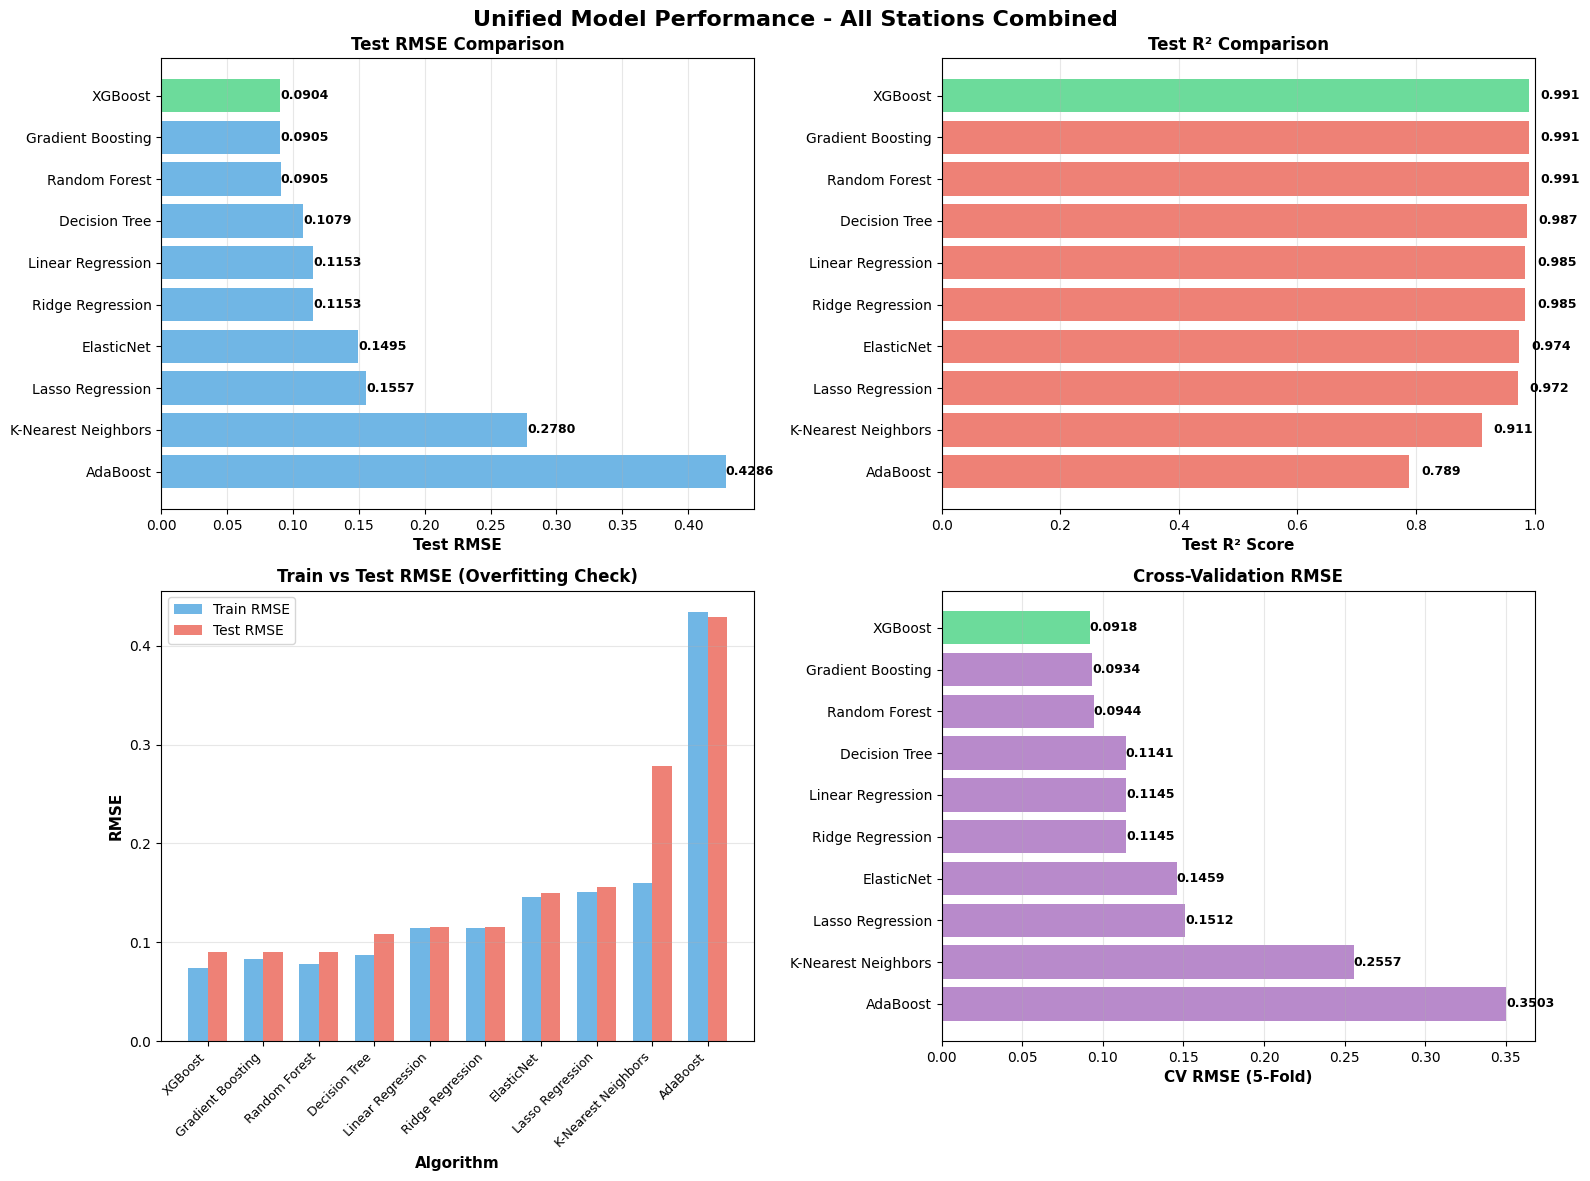

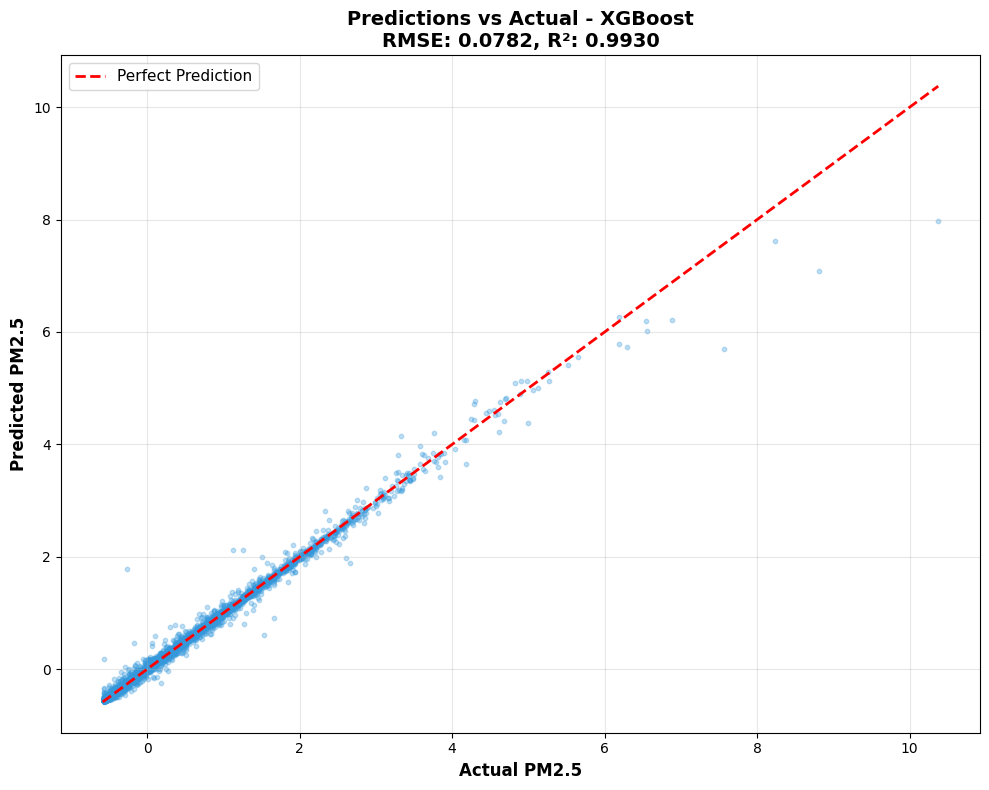

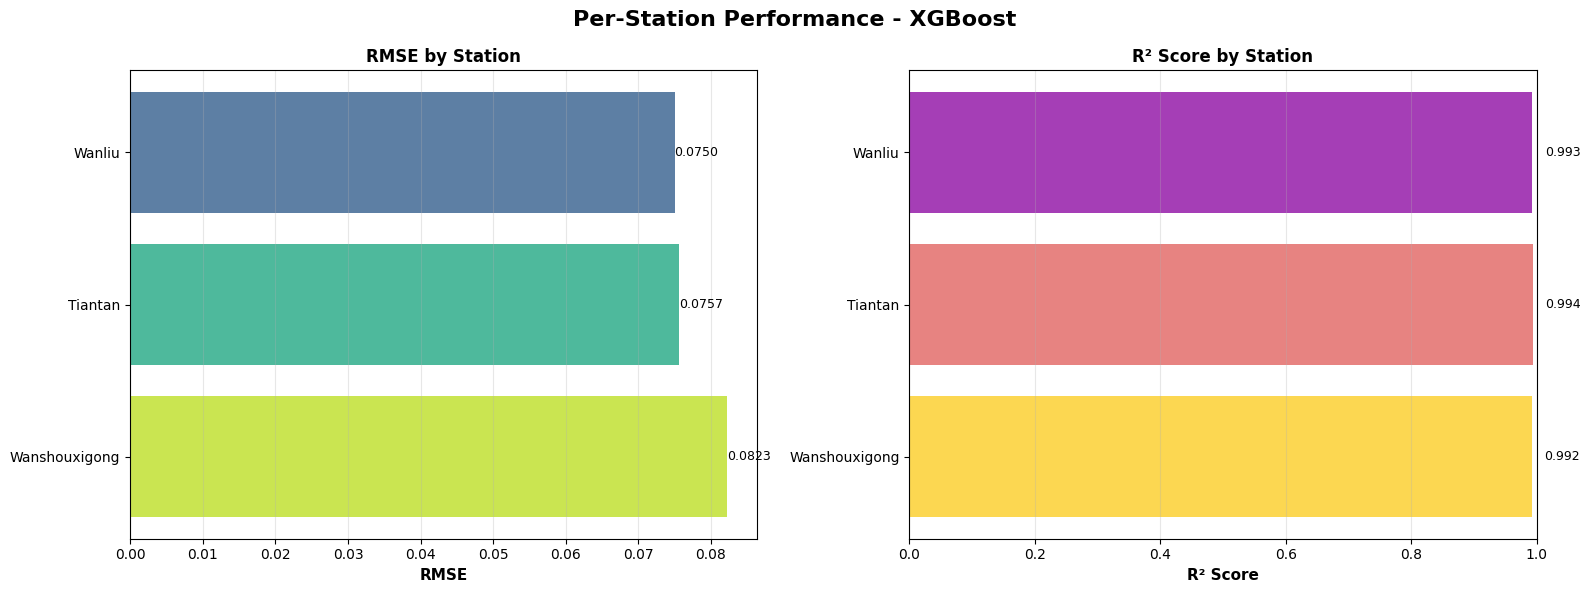

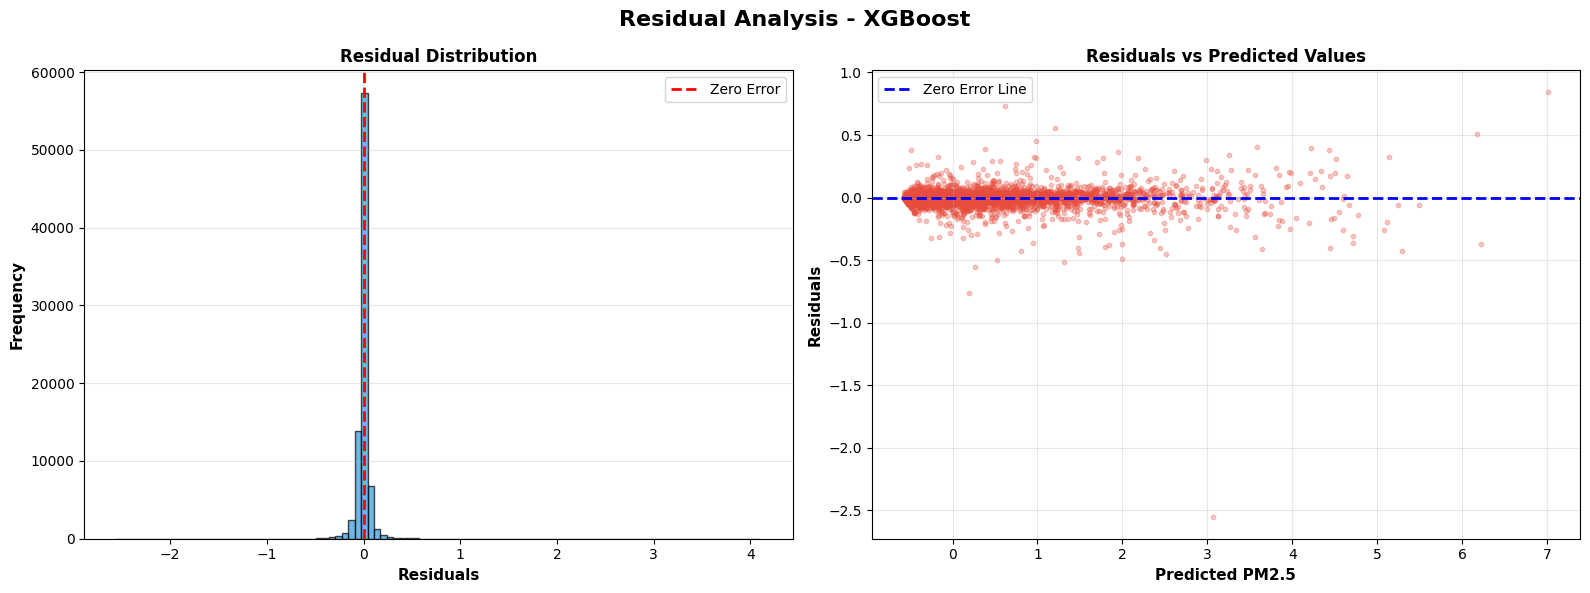

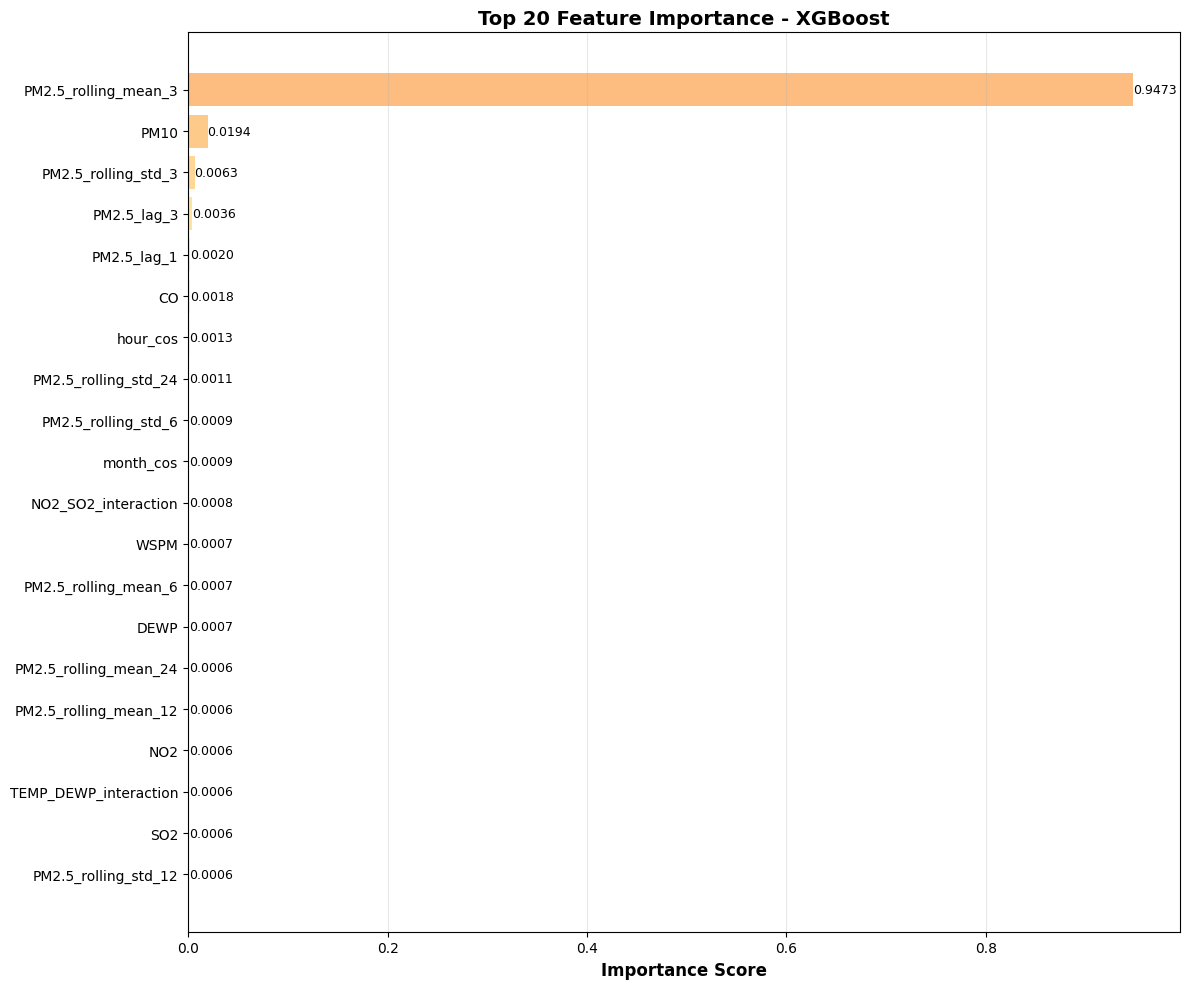

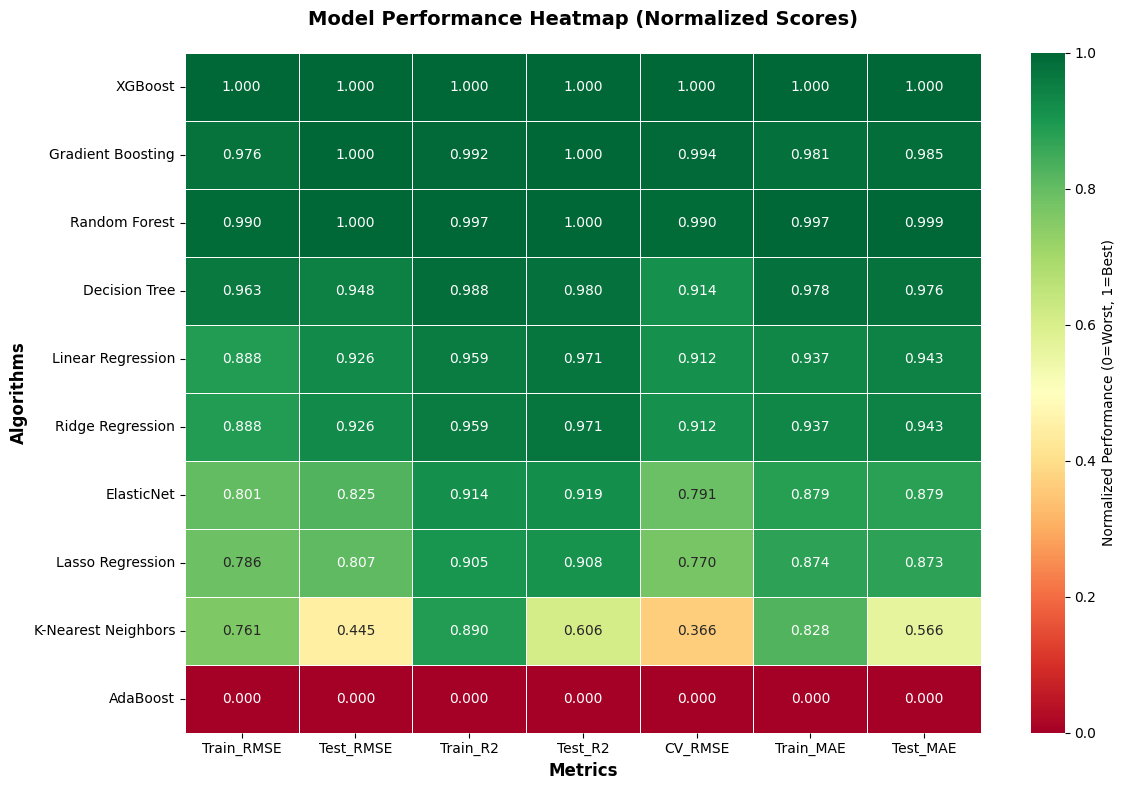

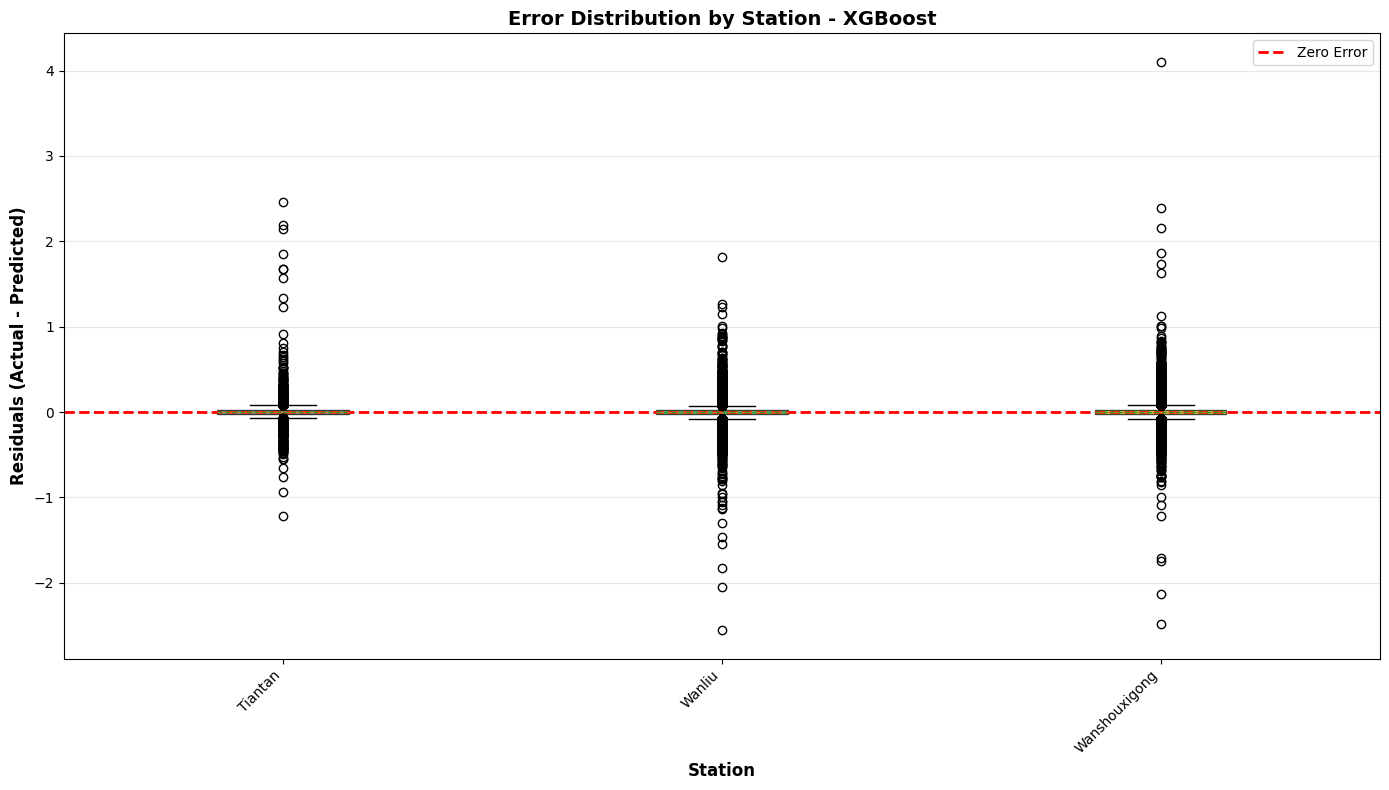

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

print("=" * 80)
print("BEIJING MULTI-SITE AIR QUALITY - UNIFIED MODEL APPROACH")
print("ONE MODEL FOR ALL 12 STATIONS")
print("=" * 80)

# ==================== LOAD ALL STATION DATA ====================
stations = {
    'Aotizhongxin': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Aotizhongxin_20130301-20170228.csv",
    'Changping': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Changping_20130301-20170228.csv",
    'Dingling': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Dingling_20130301-20170228.csv",
    'Dongsi': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Dongsi_20130301-20170228.csv",
    'Guanyuan': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Guanyuan_20130301-20170228.csv",
    'Gucheng': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Gucheng_20130301-20170228.csv",
    'Huairou': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Huairou_20130301-20170228.csv",
    'Nongzhanguan': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Nongzhanguan_20130301-20170228.csv",
    'Shunyi': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Shunyi_20130301-20170228.csv",
    'Tiantan': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Tiantan_20130301-20170228.csv",
    'Wanliu': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Wanliu_20130301-20170228.csv",
    'Wanshouxigong': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Wanshouxigong_20130301-20170228.csv"
}

print(f"\n📍 Loading data from {len(stations)} monitoring stations...")

all_station_dfs = []
for station_name, path in stations.items():
    try:
        df = pd.read_csv(path)
        df['station'] = station_name
        all_station_dfs.append(df)
        print(f"   ✓ {station_name}: {df.shape[0]} rows")
    except Exception as e:
        print(f"   ✗ {station_name}: Failed - {e}")

# Combine all stations into one dataset
combined_df = pd.concat(all_station_dfs, ignore_index=True)
print(f"\n✓ Combined dataset: {len(combined_df):,} rows from {combined_df['station'].nunique()} stations")

# ==================== PREPROCESSING ====================
print("\n" + "=" * 80)
print("STEP 1: UNIFIED PREPROCESSING")
print("=" * 80)

# Create datetime
combined_df['datetime'] = pd.to_datetime(combined_df[['year', 'month', 'day', 'hour']])

# Encode station as categorical
le = LabelEncoder()
combined_df['station_encoded'] = le.fit_transform(combined_df['station'])

# Handle wind direction
if 'wd' in combined_df.columns:
    combined_df['wd'] = combined_df['wd'].fillna('Unknown')
    wd_encoder = LabelEncoder()
    combined_df['wd_encoded'] = wd_encoder.fit_transform(combined_df['wd'])

numeric_columns = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
available_numeric = [col for col in numeric_columns if col in combined_df.columns]

print(f"\n🔧 Normalizing {len(available_numeric)} features with RobustScaler...")
scaler = RobustScaler()
combined_df[available_numeric] = scaler.fit_transform(combined_df[available_numeric])

print(f"🔧 Filling missing values with interpolation...")
combined_df = combined_df.sort_values(['station', 'datetime']).reset_index(drop=True)

for col in available_numeric:
    combined_df[col] = combined_df.groupby('station')[col].transform(
        lambda x: x.interpolate(method='linear', limit_direction='both').fillna(method='ffill').fillna(method='bfill')
    )

# ==================== FEATURE ENGINEERING ====================
print("\n" + "=" * 80)
print("STEP 2: FEATURE ENGINEERING")
print("=" * 80)

print("1️⃣ Temporal Features...")
combined_df['hour'] = combined_df['datetime'].dt.hour
combined_df['day'] = combined_df['datetime'].dt.day
combined_df['month'] = combined_df['datetime'].dt.month
combined_df['dayofweek'] = combined_df['datetime'].dt.dayofweek
combined_df['dayofyear'] = combined_df['datetime'].dt.dayofyear
combined_df['is_weekend'] = (combined_df['dayofweek'] >= 5).astype(int)

# Cyclical encoding
combined_df['hour_sin'] = np.sin(2 * np.pi * combined_df['hour'] / 24)
combined_df['hour_cos'] = np.cos(2 * np.pi * combined_df['hour'] / 24)
combined_df['month_sin'] = np.sin(2 * np.pi * combined_df['month'] / 12)
combined_df['month_cos'] = np.cos(2 * np.pi * combined_df['month'] / 12)

print("2️⃣ Lag Features (grouped by station)...")
lag_periods = [1, 3, 6, 12, 24]
for lag in lag_periods:
    combined_df[f'PM2.5_lag_{lag}'] = combined_df.groupby('station')['PM2.5'].shift(lag)
    combined_df[f'TEMP_lag_{lag}'] = combined_df.groupby('station')['TEMP'].shift(lag)

print("3️⃣ Rolling Features (grouped by station)...")
rolling_windows = [3, 6, 12, 24]
for window in rolling_windows:
    combined_df[f'PM2.5_rolling_mean_{window}'] = combined_df.groupby('station')['PM2.5'].transform(
        lambda x: x.rolling(window=window, min_periods=1).mean()
    )
    combined_df[f'PM2.5_rolling_std_{window}'] = combined_df.groupby('station')['PM2.5'].transform(
        lambda x: x.rolling(window=window, min_periods=1).std()
    )

print("4️⃣ Interaction Features...")
combined_df['TEMP_PRES_interaction'] = combined_df['TEMP'] * combined_df['PRES']
combined_df['TEMP_DEWP_interaction'] = combined_df['TEMP'] * combined_df['DEWP']
combined_df['NO2_SO2_interaction'] = combined_df['NO2'] * combined_df['SO2']

# Drop NaN rows
initial_rows = len(combined_df)
combined_df = combined_df.dropna()
print(f"\n5️⃣ Cleaned: Dropped {initial_rows - len(combined_df)} rows with NaN")
print(f"   Final dataset: {len(combined_df):,} rows")

# ==================== PREPARE DATA FOR MODELING ====================
print("\n" + "=" * 80)
print("STEP 3: PREPARING UNIFIED MODEL DATA")
print("=" * 80)

feature_cols = [col for col in combined_df.columns if col not in 
               ['datetime', 'station', 'year', 'day', 'PM2.5', 'wd', 'No']]

X = combined_df[feature_cols]
y = combined_df['PM2.5']

print(f"   Features: {len(feature_cols)}")
print(f"   Samples: {len(X):,}")
print(f"   Stations: {combined_df['station'].nunique()}")

# Train-test split (80-20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=False
)

print(f"   Training: {len(X_train):,} samples ({len(X_train)/len(X)*100:.1f}%)")
print(f"   Testing: {len(X_test):,} samples ({len(X_test)/len(X)*100:.1f}%)")

# ==================== MODEL TRAINING ====================
print("\n" + "=" * 80)
print("STEP 4: TRAINING 10 REGRESSION MODELS")
print("=" * 80)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.01, max_iter=5000),
    'ElasticNet': ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, max_depth=5, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1, verbosity=0),
    'AdaBoost': AdaBoostRegressor(n_estimators=50, random_state=42),
    'K-Nearest Neighbors': KNeighborsRegressor(n_neighbors=5)
}

results = []
predictions = {}
trained_models = {}

print("\n🔄 Training models on unified dataset...")
print("-" * 80)

for name, model in models.items():
    print(f"   Training {name}...", end=" ")
    
    model.fit(X_train, y_train)
    
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    
    train_mse = mean_squared_error(y_train, y_pred_train)
    test_mse = mean_squared_error(y_test, y_pred_test)
    train_rmse = np.sqrt(train_mse)
    test_rmse = np.sqrt(test_mse)
    train_mae = mean_absolute_error(y_train, y_pred_train)
    test_mae = mean_absolute_error(y_test, y_pred_test)
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, 
                                scoring='neg_mean_squared_error', n_jobs=-1)
    cv_rmse = np.sqrt(-cv_scores.mean())
    
    results.append({
        'Algorithm': name,
        'Train_RMSE': train_rmse,
        'Test_RMSE': test_rmse,
        'Train_MAE': train_mae,
        'Test_MAE': test_mae,
        'Train_R2': train_r2,
        'Test_R2': test_r2,
        'CV_RMSE': cv_rmse,
        'Overfit': train_rmse - test_rmse
    })
    
    predictions[name] = y_pred_test
    trained_models[name] = model
    
    print(f"✓ RMSE: {test_rmse:.4f}, R²: {test_r2:.4f}")

results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Test_RMSE')

# ==================== RESULTS ====================
print("\n" + "=" * 80)
print("RESULTS: UNIFIED MODEL PERFORMANCE")
print("=" * 80)

print("\n📊 Model Performance Ranking:")
print("-" * 80)
print(results_df.to_string(index=False))

best_model_name = results_df.iloc[0]['Algorithm']
best_rmse = results_df.iloc[0]['Test_RMSE']
best_r2 = results_df.iloc[0]['Test_R2']

print(f"\n🏆 BEST MODEL: {best_model_name}")
print(f"   Test RMSE: {best_rmse:.4f}")
print(f"   Test R²: {best_r2:.4f}")
print(f"   Test MAE: {results_df.iloc[0]['Test_MAE']:.4f}")
print(f"   CV RMSE: {results_df.iloc[0]['CV_RMSE']:.4f}")
print(f"   Overfitting: {results_df.iloc[0]['Overfit']:.4f}")

# ==================== HYPERPARAMETER OPTIMIZATION ====================
print("\n" + "=" * 80)
print("STEP 5: HYPERPARAMETER OPTIMIZATION (Best Model)")
print("=" * 80)

print(f"\n🔧 Optimizing {best_model_name}...")

if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 150, 200],
        'max_depth': [10, 15, 20],
        'min_samples_split': [2, 5, 10]
    }
    base_model = RandomForestRegressor(random_state=42, n_jobs=-1)
    
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 150, 200],
        'max_depth': [5, 7, 10],
        'learning_rate': [0.01, 0.05, 0.1]
    }
    base_model = XGBRegressor(random_state=42, n_jobs=-1, verbosity=0)
    
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 150, 200],
        'max_depth': [5, 7, 10],
        'learning_rate': [0.01, 0.05, 0.1]
    }
    base_model = GradientBoostingRegressor(random_state=42)
    
elif best_model_name == 'Ridge Regression':
    param_grid = {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}
    base_model = Ridge()
    
elif best_model_name == 'Lasso Regression':
    param_grid = {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0]}
    base_model = Lasso(max_iter=5000)
    
elif best_model_name == 'Decision Tree':
    param_grid = {
        'max_depth': [10, 15, 20, 25],
        'min_samples_split': [2, 5, 10]
    }
    base_model = DecisionTreeRegressor(random_state=42)
    
else:
    param_grid = {}
    base_model = trained_models[best_model_name]

if param_grid:
    grid_search = GridSearchCV(base_model, param_grid, cv=5, 
                               scoring='neg_mean_squared_error', n_jobs=-1)
    grid_search.fit(X_train, y_train)
    
    best_model = grid_search.best_estimator_
    y_pred_opt = best_model.predict(X_test)
    
    opt_rmse = np.sqrt(mean_squared_error(y_test, y_pred_opt))
    opt_r2 = r2_score(y_test, y_pred_opt)
    opt_mae = mean_absolute_error(y_test, y_pred_opt)
    
    improvement = best_rmse - opt_rmse
    
    print(f"   Best params: {grid_search.best_params_}")
    print(f"   Optimized RMSE: {opt_rmse:.4f} (improvement: {improvement:.4f})")
    print(f"   Optimized R²: {opt_r2:.4f}")
    print(f"   Optimized MAE: {opt_mae:.4f}")
    
    # Use optimized model
    best_model_obj = best_model
    best_predictions = y_pred_opt
    final_rmse = opt_rmse
    final_r2 = opt_r2
    final_mae = opt_mae
else:
    best_model_obj = trained_models[best_model_name]
    best_predictions = predictions[best_model_name]
    final_rmse = best_rmse
    final_r2 = best_r2
    final_mae = results_df.iloc[0]['Test_MAE']

# ==================== PER-STATION ANALYSIS ====================
print("\n" + "=" * 80)
print("STEP 6: PER-STATION PERFORMANCE ANALYSIS")
print("=" * 80)

# Get station info for test set
test_indices = X_test.index
test_stations = combined_df.loc[test_indices, 'station']

station_performance = []
for station in combined_df['station'].unique():
    station_mask = test_stations == station
    if station_mask.sum() > 0:
        y_true_station = y_test[station_mask]
        y_pred_station = best_predictions[station_mask]
        
        station_rmse = np.sqrt(mean_squared_error(y_true_station, y_pred_station))
        station_r2 = r2_score(y_true_station, y_pred_station)
        station_mae = mean_absolute_error(y_true_station, y_pred_station)
        
        station_performance.append({
            'Station': station,
            'RMSE': station_rmse,
            'R2': station_r2,
            'MAE': station_mae,
            'Samples': station_mask.sum()
        })

station_perf_df = pd.DataFrame(station_performance).sort_values('RMSE')

print("\n📍 Performance by Station:")
print("-" * 80)
print(station_perf_df.to_string(index=False))

print(f"\n📊 Station Statistics:")
print(f"   Best Station (lowest RMSE): {station_perf_df.iloc[0]['Station']} (RMSE: {station_perf_df.iloc[0]['RMSE']:.4f})")
print(f"   Worst Station (highest RMSE): {station_perf_df.iloc[-1]['Station']} (RMSE: {station_perf_df.iloc[-1]['RMSE']:.4f})")
print(f"   Average RMSE across stations: {station_perf_df['RMSE'].mean():.4f}")
print(f"   Average R² across stations: {station_perf_df['R2'].mean():.4f}")

# ==================== FEATURE IMPORTANCE ====================
if best_model_name in ['Random Forest', 'Gradient Boosting', 'XGBoost', 'Decision Tree']:
    print("\n" + "=" * 80)
    print("STEP 7: FEATURE IMPORTANCE ANALYSIS")
    print("=" * 80)
    
    feature_importance = pd.DataFrame({
        'Feature': feature_cols,
        'Importance': best_model_obj.feature_importances_
    }).sort_values('Importance', ascending=False).head(20)
    
    print("\n🎯 Top 20 Important Features:")
    print("-" * 80)
    for i, row in feature_importance.iterrows():
        print(f"   {row['Feature']}: {row['Importance']:.4f}")

# ==================== VISUALIZATIONS ====================
print("\n" + "=" * 80)
print("GENERATING VISUALIZATIONS")
print("=" * 80)

# Figure 1: Model Comparison
fig1, axes = plt.subplots(2, 2, figsize=(16, 12))
fig1.suptitle('Unified Model Performance - All Stations Combined', fontsize=16, fontweight='bold')

# Test RMSE
ax1 = axes[0, 0]
colors = ['#2ecc71' if i == 0 else '#3498db' for i in range(len(results_df))]
bars = ax1.barh(results_df['Algorithm'], results_df['Test_RMSE'], color=colors, alpha=0.7)
ax1.set_xlabel('Test RMSE', fontsize=11, fontweight='bold')
ax1.set_title('Test RMSE Comparison', fontweight='bold', fontsize=12)
ax1.invert_yaxis()
ax1.grid(True, alpha=0.3, axis='x')
for bar in bars:
    width = bar.get_width()
    ax1.text(width, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
            ha='left', va='center', fontsize=9, fontweight='bold')

# Test R²
ax2 = axes[0, 1]
colors = ['#2ecc71' if i == 0 else '#e74c3c' for i in range(len(results_df))]
bars = ax2.barh(results_df['Algorithm'], results_df['Test_R2'], color=colors, alpha=0.7)
ax2.set_xlabel('Test R² Score', fontsize=11, fontweight='bold')
ax2.set_title('Test R² Comparison', fontweight='bold', fontsize=12)
ax2.invert_yaxis()
ax2.set_xlim([0, 1])
ax2.grid(True, alpha=0.3, axis='x')
for bar in bars:
    width = bar.get_width()
    ax2.text(width + 0.02, bar.get_y() + bar.get_height()/2, f'{width:.3f}',
            ha='left', va='center', fontsize=9, fontweight='bold')

# Train vs Test RMSE
ax3 = axes[1, 0]
x = np.arange(len(results_df))
width = 0.35
bars1 = ax3.bar(x - width/2, results_df['Train_RMSE'], width, label='Train RMSE', 
               color='#3498db', alpha=0.7)
bars2 = ax3.bar(x + width/2, results_df['Test_RMSE'], width, label='Test RMSE', 
               color='#e74c3c', alpha=0.7)
ax3.set_xlabel('Algorithm', fontsize=11, fontweight='bold')
ax3.set_ylabel('RMSE', fontsize=11, fontweight='bold')
ax3.set_title('Train vs Test RMSE (Overfitting Check)', fontweight='bold', fontsize=12)
ax3.set_xticks(x)
ax3.set_xticklabels(results_df['Algorithm'], rotation=45, ha='right', fontsize=9)
ax3.legend(fontsize=10)
ax3.grid(True, alpha=0.3, axis='y')

# CV RMSE
ax4 = axes[1, 1]
colors = ['#2ecc71' if i == 0 else '#9b59b6' for i in range(len(results_df))]
bars = ax4.barh(results_df['Algorithm'], results_df['CV_RMSE'], color=colors, alpha=0.7)
ax4.set_xlabel('CV RMSE (5-Fold)', fontsize=11, fontweight='bold')
ax4.set_title('Cross-Validation RMSE', fontweight='bold', fontsize=12)
ax4.invert_yaxis()
ax4.grid(True, alpha=0.3, axis='x')
for bar in bars:
    width = bar.get_width()
    ax4.text(width, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
            ha='left', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('unified_model_comparison.png', dpi=300, bbox_inches='tight')
print("✓ Saved: unified_model_comparison.png")

# Figure 2: Predictions vs Actual
fig2, ax = plt.subplots(figsize=(10, 8))
sample_size = min(5000, len(y_test))
indices = np.random.choice(len(y_test), sample_size, replace=False)

ax.scatter(y_test.iloc[indices], best_predictions[indices], alpha=0.3, s=10, color='#3498db')
min_val = min(y_test.min(), best_predictions.min())
max_val = max(y_test.max(), best_predictions.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')

ax.set_xlabel('Actual PM2.5', fontsize=12, fontweight='bold')
ax.set_ylabel('Predicted PM2.5', fontsize=12, fontweight='bold')
ax.set_title(f'Predictions vs Actual - {best_model_name}\nRMSE: {final_rmse:.4f}, R²: {final_r2:.4f}', 
            fontweight='bold', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('unified_predictions_vs_actual.png', dpi=300, bbox_inches='tight')
print("✓ Saved: unified_predictions_vs_actual.png")

# Figure 3: Station Performance
fig3, axes = plt.subplots(1, 2, figsize=(16, 6))
fig3.suptitle(f'Per-Station Performance - {best_model_name}', fontsize=16, fontweight='bold')

ax1 = axes[0]
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(station_perf_df)))
bars = ax1.barh(station_perf_df['Station'], station_perf_df['RMSE'], color=colors, alpha=0.8)
ax1.set_xlabel('RMSE', fontsize=11, fontweight='bold')
ax1.set_title('RMSE by Station', fontweight='bold', fontsize=12)
ax1.invert_yaxis()
ax1.grid(True, alpha=0.3, axis='x')
for bar in bars:
    width = bar.get_width()
    ax1.text(width, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
            ha='left', va='center', fontsize=9)

ax2 = axes[1]
colors = plt.cm.plasma(np.linspace(0.3, 0.9, len(station_perf_df)))
bars = ax2.barh(station_perf_df['Station'], station_perf_df['R2'], color=colors, alpha=0.8)
ax2.set_xlabel('R² Score', fontsize=11, fontweight='bold')
ax2.set_title('R² Score by Station', fontweight='bold', fontsize=12)
ax2.invert_yaxis()
ax2.set_xlim([0, 1])
ax2.grid(True, alpha=0.3, axis='x')
for bar in bars:
    width = bar.get_width()
    ax2.text(width + 0.02, bar.get_y() + bar.get_height()/2, f'{width:.3f}',
            ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('station_performance_comparison.png', dpi=300, bbox_inches='tight')
print("✓ Saved: station_performance_comparison.png")

# Figure 4: Residuals Analysis
fig4, axes = plt.subplots(1, 2, figsize=(16, 6))
fig4.suptitle(f'Residual Analysis - {best_model_name}', fontsize=16, fontweight='bold')

# Calculate residuals
residuals = y_test - best_predictions

# Residual Distribution
ax1 = axes[0]
ax1.hist(residuals, bins=100, color='#3498db', alpha=0.7, edgecolor='black')
ax1.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Zero Error')
ax1.set_xlabel('Residuals', fontsize=11, fontweight='bold')
ax1.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax1.set_title('Residual Distribution', fontweight='bold', fontsize=12)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3, axis='y')

# Residual vs Predicted
ax2 = axes[1]
sample_size = min(5000, len(residuals))
indices = np.random.choice(len(residuals), sample_size, replace=False)
ax2.scatter(best_predictions[indices], residuals.iloc[indices], alpha=0.3, s=10, color='#e74c3c')
ax2.axhline(y=0, color='blue', linestyle='--', linewidth=2, label='Zero Error Line')
ax2.set_xlabel('Predicted PM2.5', fontsize=11, fontweight='bold')
ax2.set_ylabel('Residuals', fontsize=11, fontweight='bold')
ax2.set_title('Residuals vs Predicted Values', fontweight='bold', fontsize=12)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('unified_residuals_analysis.png', dpi=300, bbox_inches='tight')
print("✓ Saved: unified_residuals_analysis.png")

# Figure 5: Feature Importance (only for tree-based models)
if best_model_name in ['Random Forest', 'Gradient Boosting', 'XGBoost', 'Decision Tree']:
    print("\n📊 Generating Feature Importance Plot...")
    
    feature_importance = pd.DataFrame({
        'Feature': feature_cols,
        'Importance': best_model_obj.feature_importances_
    }).sort_values('Importance', ascending=False).head(20)
    
    fig5, ax = plt.subplots(figsize=(12, 10))
    colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(feature_importance)))
    bars = ax.barh(feature_importance['Feature'], feature_importance['Importance'], 
                   color=colors, alpha=0.8)
    ax.set_xlabel('Importance Score', fontsize=12, fontweight='bold')
    ax.set_title(f'Top 20 Feature Importance - {best_model_name}', 
                fontweight='bold', fontsize=14)
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3, axis='x')
    
    for bar in bars:
        width = bar.get_width()
        ax.text(width, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
                ha='left', va='center', fontsize=9)
    
    plt.tight_layout()
    plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
    print("✓ Saved: feature_importance.png")

# Figure 6: Model Comparison Summary Heatmap
print("\n📊 Generating Model Comparison Heatmap...")

fig6, ax = plt.subplots(figsize=(12, 8))

# Prepare data for heatmap (normalize metrics to 0-1 scale)
heatmap_data = results_df[['Algorithm', 'Train_RMSE', 'Test_RMSE', 'Train_R2', 
                            'Test_R2', 'CV_RMSE', 'Train_MAE', 'Test_MAE']].copy()
heatmap_data = heatmap_data.set_index('Algorithm')

# Normalize (inverse for error metrics, direct for R2)
for col in ['Train_RMSE', 'Test_RMSE', 'CV_RMSE', 'Train_MAE', 'Test_MAE']:
    heatmap_data[col] = 1 - (heatmap_data[col] - heatmap_data[col].min()) / (heatmap_data[col].max() - heatmap_data[col].min())

for col in ['Train_R2', 'Test_R2']:
    heatmap_data[col] = (heatmap_data[col] - heatmap_data[col].min()) / (heatmap_data[col].max() - heatmap_data[col].min())

# Create heatmap
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='RdYlGn', 
            cbar_kws={'label': 'Normalized Performance (0=Worst, 1=Best)'},
            linewidths=0.5, ax=ax)
ax.set_title('Model Performance Heatmap (Normalized Scores)', 
             fontweight='bold', fontsize=14, pad=20)
ax.set_xlabel('Metrics', fontsize=12, fontweight='bold')
ax.set_ylabel('Algorithms', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison_heatmap.png', dpi=300, bbox_inches='tight')
print("✓ Saved: model_comparison_heatmap.png")

# Figure 7: Error Distribution by Station
print("\n📊 Generating Station Error Distribution...")

fig7, ax = plt.subplots(figsize=(14, 8))

station_residuals = []
station_labels = []

for station in combined_df['station'].unique():
    station_mask = test_stations == station
    if station_mask.sum() > 0:
        station_resid = y_test[station_mask] - best_predictions[station_mask]
        station_residuals.append(station_resid)
        station_labels.append(station)

bp = ax.boxplot(station_residuals, labels=station_labels, patch_artist=True,
                showmeans=True, meanline=True)

# Color the boxes
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(station_labels)))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error')
ax.set_xlabel('Station', fontsize=12, fontweight='bold')
ax.set_ylabel('Residuals (Actual - Predicted)', fontsize=12, fontweight='bold')
ax.set_title(f'Error Distribution by Station - {best_model_name}', 
             
             fontweight='bold', fontsize=14)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('station_error_distribution.png', dpi=300, bbox_inches='tight')
print("✓ Saved: station_error_distribution.png")

# ==================== SUMMARY ====================
print("\n" + "=" * 80)
print("VISUALIZATION COMPLETE")
print("=" * 80)
print("\n📁 Generated Files:")
print("   1. unified_model_comparison.png - Overall model performance comparison")
print("   2. unified_predictions_vs_actual.png - Prediction accuracy scatter plot")
print("   3. station_performance_comparison.png - Per-station RMSE and R² scores")
print("   4. unified_residuals_analysis.png - Residual distribution and patterns")
if best_model_name in ['Random Forest', 'Gradient Boosting', 'XGBoost', 'Decision Tree']:
    print("   5. feature_importance.png - Top 20 most important features")
print(f"   {5 if best_model_name in ['Random Forest', 'Gradient Boosting', 'XGBoost', 'Decision Tree'] else 5}. model_comparison_heatmap.png - Normalized performance heatmap")
print(f"   {6 if best_model_name in ['Random Forest', 'Gradient Boosting', 'XGBoost', 'Decision Tree'] else 6}. station_error_distribution.png - Error boxplots by station")

print("\n✅ Analysis Complete!")
print("=" * 80)

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from xgboost import XGBRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')


print("=" * 80)
print("BEIJING MULTI-SITE AIR QUALITY - UNIFIED MODEL APPROACH")
print("ONE MODEL FOR ALL 12 STATIONS")
print("=" * 80)


# ================================================================
# LOAD ALL STATION DATA
# ================================================================

stations = {
    'Aotizhongxin': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Aotizhongxin_20130301-20170228.csv",
    'Changping': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Changping_20130301-20170228.csv",
    'Dingling': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Dingling_20130301-20170228.csv",
    'Dongsi': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Dongsi_20130301-20170228.csv",
    'Guanyuan': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Guanyuan_20130301-20170228.csv",
    'Gucheng': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Gucheng_20130301-20170228.csv",
    'Huairou': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Huairou_20130301-20170228.csv",
    'Nongzhanguan': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Nongzhanguan_20130301-20170228.csv",
    'Shunyi': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Shunyi_20130301-20170228.csv",
    'Tiantan': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Tiantan_20130301-20170228.csv",
    'Wanliu': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Wanliu_20130301-20170228.csv",
    'Wanshouxigong': "C:\\Users\\hanus\\Downloads\\beijing+multi+site+air+quality+data\\PRSA2017_Data_20130301-20170228\\PRSA_Data_20130301-20170228\\PRSA_Data_Wanshouxigong_20130301-20170228.csv"
}


print(f"\n📍 Loading data from {len(stations)} monitoring stations...")

all_station_dfs = []

for station_name, path in stations.items():

    try:

        df = pd.read_csv(path)

        df['station'] = station_name

        all_station_dfs.append(df)

        print(f"   ✓ {station_name}: {df.shape[0]} rows")

    except Exception as e:

        print(f"   ✗ {station_name}: Failed - {e}")


if len(all_station_dfs) == 0:

    raise ValueError("No station datasets were loaded successfully.")

# Combine all stations
combined_df = pd.concat(
    all_station_dfs,
    ignore_index=True
)

print(
    f"\n✓ Combined dataset: {len(combined_df):,} rows "
    f"from {combined_df['station'].nunique()} stations"
)


# ================================================================
# STEP 1: UNIFIED PREPROCESSING
# ================================================================

print("\n" + "=" * 80)
print("STEP 1: UNIFIED PREPROCESSING")
print("=" * 80)

# Create datetime
combined_df['datetime'] = pd.to_datetime(
    combined_df[['year', 'month', 'day', 'hour']],
    errors='coerce'
)

combined_df = combined_df.dropna(
    subset=['datetime']
)

# Encode station
le = LabelEncoder()

combined_df['station_encoded'] = le.fit_transform(
    combined_df['station']
)

# Handle wind direction
if 'wd' in combined_df.columns:

    combined_df['wd'] = combined_df['wd'].fillna('Unknown')

    wd_encoder = LabelEncoder()

    combined_df['wd_encoded'] = wd_encoder.fit_transform(
        combined_df['wd']
    )

numeric_columns = [
    'PM2.5', 'PM10', 'SO2', 'NO2', 'CO',
    'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM'
]

available_numeric = [
    col for col in numeric_columns
    if col in combined_df.columns
]

# Convert numeric columns
for col in available_numeric:

    combined_df[col] = pd.to_numeric(
        combined_df[col],
        errors='coerce'
    )

# Sort by station and time
combined_df = combined_df.sort_values(
    ['station', 'datetime']
).reset_index(drop=True)

# IMPORTANT:
# No global RobustScaler is applied here.
# Scaling will be fitted only on training data later.

print(f"\n🔧 Available numeric features: {len(available_numeric)}")

print("\n🔧 Filling missing input values using past values only...")

# Forward fill within each station only.
# No interpolation or backward fill because that uses future data.
for col in available_numeric:

    if col != 'PM2.5':

        combined_df[col] = (
            combined_df.groupby('station')[col]
            .ffill()
        )

if 'wd' in combined_df.columns:

    combined_df['wd'] = (
        combined_df.groupby('station')['wd']
        .ffill()
    )

# PM2.5 target is NOT imputed.
# Rows with missing target will be removed later.


# ================================================================
# STEP 2: FEATURE ENGINEERING
# ================================================================

print("\n" + "=" * 80)
print("STEP 2: FEATURE ENGINEERING")
print("=" * 80)

print("1️⃣ Temporal Features...")

combined_df['hour'] = combined_df['datetime'].dt.hour

combined_df['day'] = combined_df['datetime'].dt.day

combined_df['month'] = combined_df['datetime'].dt.month

combined_df['dayofweek'] = combined_df['datetime'].dt.dayofweek

combined_df['dayofyear'] = combined_df['datetime'].dt.dayofyear

combined_df['is_weekend'] = (
    combined_df['dayofweek'] >= 5
).astype(int)

# Cyclical encoding
combined_df['hour_sin'] = np.sin(
    2 * np.pi * combined_df['hour'] / 24
)

combined_df['hour_cos'] = np.cos(
    2 * np.pi * combined_df['hour'] / 24
)

combined_df['month_sin'] = np.sin(
    2 * np.pi * combined_df['month'] / 12
)

combined_df['month_cos'] = np.cos(
    2 * np.pi * combined_df['month'] / 12
)


# ------------------------------------------------
# 2. LAG FEATURES
# ------------------------------------------------

print("2️⃣ Lag Features (grouped by station)...")

lag_periods = [1, 3, 6, 12, 24]

for lag in lag_periods:

    combined_df[f'PM2.5_lag_{lag}'] = (
        combined_df.groupby('station')['PM2.5']
        .shift(lag)
    )

    if 'TEMP' in combined_df.columns:

        combined_df[f'TEMP_lag_{lag}'] = (
            combined_df.groupby('station')['TEMP']
            .shift(lag)
        )


# ------------------------------------------------
# 3. ROLLING FEATURES - CORRECTED
# ------------------------------------------------

print("3️⃣ Rolling Features (leakage corrected)...")

rolling_windows = [3, 6, 12, 24]

# Shift PM2.5 by one timestep FIRST.
# This ensures current PM2.5 is not included in rolling features.
previous_pm = (
    combined_df.groupby('station')['PM2.5']
    .shift(1)
)

for window in rolling_windows:

    combined_df[f'PM2.5_rolling_mean_{window}'] = (
        previous_pm.groupby(combined_df['station'])
        .transform(
            lambda x: x.rolling(
                window=window,
                min_periods=1
            ).mean()
        )
    )

    combined_df[f'PM2.5_rolling_std_{window}'] = (
        previous_pm.groupby(combined_df['station'])
        .transform(
            lambda x: x.rolling(
                window=window,
                min_periods=2
            ).std()
        )
    )


# ------------------------------------------------
# 4. INTERACTION FEATURES
# ------------------------------------------------

print("4️⃣ Interaction Features...")

if all(col in combined_df.columns for col in ['TEMP', 'PRES']):

    combined_df['TEMP_PRES_interaction'] = (
        combined_df['TEMP'] * combined_df['PRES']
    )

if all(col in combined_df.columns for col in ['TEMP', 'DEWP']):

    combined_df['TEMP_DEWP_interaction'] = (
        combined_df['TEMP'] * combined_df['DEWP']
    )

if all(col in combined_df.columns for col in ['NO2', 'SO2']):

    combined_df['NO2_SO2_interaction'] = (
        combined_df['NO2'] * combined_df['SO2']
    )


# ------------------------------------------------
# 5. REMOVE MISSING TARGET
# ------------------------------------------------

initial_rows = len(combined_df)

# Remove only rows with missing target.
combined_df = combined_df.dropna(
    subset=['PM2.5']
).copy()

print(
    f"\n5️⃣ Removed {initial_rows - len(combined_df)} "
    "rows with missing PM2.5 target"
)

print(
    f"   Dataset: {len(combined_df):,} rows"
)


# ================================================================
# STEP 3: PREPARE DATA FOR MODELING
# ================================================================

print("\n" + "=" * 80)
print("STEP 3: PREPARING UNIFIED MODEL DATA")
print("=" * 80)

# Feature columns
feature_cols = [
    col for col in combined_df.columns
    if col not in [
        'datetime',
        'station',
        'year',
        'day',
        'PM2.5',
        'wd',
        'No'
    ]
]

X = combined_df[feature_cols].copy()

y = combined_df['PM2.5'].copy()

print(f"   Features: {len(feature_cols)}")

print(f"   Samples: {len(X):,}")

print(f"   Stations: {combined_df['station'].nunique()}")


# ================================================================
# STEP 4: CHRONOLOGICAL TRAIN/TEST SPLIT PER STATION
# ================================================================

print("\nCreating chronological train/test split per station...")

train_parts = []

test_parts = []

TEST_SIZE = 0.20

for station_name, station_data in combined_df.groupby(
    'station',
    sort=False
):

    station_data = station_data.sort_values(
        'datetime'
    ).reset_index(drop=True)

    split_idx = int(
        len(station_data) * (1 - TEST_SIZE)
    )

    split_idx = max(
        1,
        min(split_idx, len(station_data) - 1)
    )

    station_train = station_data.iloc[
        :split_idx
    ].copy()

    station_test = station_data.iloc[
        split_idx:
    ].copy()

    train_parts.append(station_train)

    test_parts.append(station_test)

    print(
        f"   {station_name}: "
        f"Train={len(station_train):,}, "
        f"Test={len(station_test):,}"
    )

train_df = pd.concat(
    train_parts,
    ignore_index=True
)

test_df = pd.concat(
    test_parts,
    ignore_index=True
)

train_df = train_df.sort_values(
    ['station', 'datetime']
).reset_index(drop=True)

test_df = test_df.sort_values(
    ['station', 'datetime']
).reset_index(drop=True)


# ================================================================
# STEP 5: CHRONOLOGICAL TRAIN/VALIDATION SPLIT
# ================================================================

# Validation is used for model selection.
# The test set is not used to select the best model.

VALIDATION_SIZE = 0.10

fit_parts = []

validation_parts = []

for station_name, station_data in train_df.groupby(
    'station',
    sort=False
):

    station_data = station_data.sort_values(
        'datetime'
    ).reset_index(drop=True)

    split_idx = int(
        len(station_data) * (1 - VALIDATION_SIZE)
    )

    split_idx = max(
        1,
        min(split_idx, len(station_data) - 1)
    )

    fit_parts.append(
        station_data.iloc[:split_idx].copy()
    )

    validation_parts.append(
        station_data.iloc[split_idx:].copy()
    )

fit_df = pd.concat(
    fit_parts,
    ignore_index=True
)

validation_df = pd.concat(
    validation_parts,
    ignore_index=True
)

fit_df = fit_df.sort_values(
    ['station', 'datetime']
).reset_index(drop=True)

validation_df = validation_df.sort_values(
    ['station', 'datetime']
).reset_index(drop=True)

print(f"\n   Fit samples: {len(fit_df):,}")

print(f"   Validation samples: {len(validation_df):,}")

print(f"   Test samples: {len(test_df):,}")


# ================================================================
# STEP 6: PREPROCESSING - FIT ONLY ON TRAINING DATA
# ================================================================

print("\nFitting imputer and RobustScaler only on training data...")

# Numeric feature data
X_fit_raw = fit_df[feature_cols].copy()

X_validation_raw = validation_df[feature_cols].copy()

X_train_raw = train_df[feature_cols].copy()

X_test_raw = test_df[feature_cols].copy()

y_fit = fit_df['PM2.5'].copy()

y_validation = validation_df['PM2.5'].copy()

y_train = train_df['PM2.5'].copy()

y_test = test_df['PM2.5'].copy()


# Imputer fitted only on fit subset
imputer = SimpleImputer(
    strategy='median'
)

X_fit_imputed = imputer.fit_transform(
    X_fit_raw
)

X_validation_imputed = imputer.transform(
    X_validation_raw
)

# RobustScaler fitted only on fit subset
scaler = RobustScaler()

X_fit = scaler.fit_transform(
    X_fit_imputed
)

X_validation = scaler.transform(
    X_validation_imputed
)

# Full train and test data are transformed with the same
# training-fitted imputer/scaler for model comparison.
X_train = scaler.transform(
    imputer.transform(X_train_raw)
)

X_test = scaler.transform(
    imputer.transform(X_test_raw)
)

print("   ✓ Imputer fitted on training data")
print("   ✓ RobustScaler fitted on training data")
print("   ✓ Validation and test data transformed without fitting")


# ================================================================
# STEP 7: MODEL TRAINING
# ================================================================

print("\n" + "=" * 80)
print("STEP 4: TRAINING 10 REGRESSION MODELS")
print("=" * 80) 

models = {
    'Linear Regression': LinearRegression(),

    'Ridge Regression': Ridge(alpha=1.0),

    'Lasso Regression': Lasso(
        alpha=0.01,
        max_iter=5000
    ),

    'ElasticNet': ElasticNet(
        alpha=0.01,
        l1_ratio=0.5,
        max_iter=5000
    ),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ),

    'XGBoost': XGBRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=42,
        n_jobs=-1,
        verbosity=0
    ),

    'AdaBoost': AdaBoostRegressor(
        n_estimators=50,
        random_state=42
    ),

    'K-Nearest Neighbors': KNeighborsRegressor(
        n_neighbors=5
    )
}


# ================================================================
# TIME SERIES CROSS VALIDATION
# ================================================================

tscv = TimeSeriesSplit(
    n_splits=5
)


# ================================================================
# METRIC FUNCTION
# ================================================================

def calculate_metrics(y_true, y_pred):

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return rmse, mae, r2


results = []

predictions = {}

trained_models = {}

validation_predictions = {}

print("\n🔄 Training models on unified dataset...")
print("-" * 80)


for name, model in models.items():

    print(f"   Training {name}...", end=" ")

    try:

        model.fit(
            X_fit,
            y_fit
        )

        # Predictions on fit subset
        y_pred_train = model.predict(
            X_fit
        )

        # Predictions on validation subset
        y_pred_validation = model.predict(
            X_validation
        )

        # Metrics
        train_rmse, train_mae, train_r2 = calculate_metrics(
            y_fit,
            y_pred_train
        )

        val_rmse, val_mae, val_r2 = calculate_metrics(
            y_validation,
            y_pred_validation
        )

        # Time series CV on fit subset
        cv_scores = []

        for train_idx, val_idx in tscv.split(X_fit):

            X_cv_train = X_fit[train_idx]

            X_cv_val = X_fit[val_idx]

            y_cv_train = y_fit.iloc[train_idx]

            y_cv_val = y_fit.iloc[val_idx]

            cv_model = models[name]

            cv_model.fit(
                X_cv_train,
                y_cv_train
            )

            cv_pred = cv_model.predict(
                X_cv_val
            )

            cv_rmse = np.sqrt(
                mean_squared_error(
                    y_cv_val,
                    cv_pred
                )
            )

            cv_scores.append(cv_rmse)

        cv_rmse = np.mean(cv_scores)

        results.append({
            'Algorithm': name,
            'Train_RMSE': train_rmse,
            'Validation_RMSE': val_rmse,
            'Train_MAE': train_mae,
            'Validation_MAE': val_mae,
            'Train_R2': train_r2,
            'Validation_R2': val_r2,
            'CV_RMSE': cv_rmse,
            'Overfit': train_rmse - val_rmse
        })

        validation_predictions[name] = y_pred_validation

        trained_models[name] = model

        print(
            f"✓ Validation RMSE: {val_rmse:.4f}, "
            f"Validation R²: {val_r2:.4f}, "
            f"CV RMSE: {cv_rmse:.4f}"
        )

    except Exception as e:

        print(f"✗ Failed: {e}")


# ================================================================
# STEP 8: MODEL RESULTS
# ================================================================

results_df = pd.DataFrame(
    results
)

results_df = results_df.sort_values(
    'Validation_RMSE'
).reset_index(drop=True)

print("\n" + "=" * 80)
print("RESULTS: UNIFIED MODEL PERFORMANCE")
print("=" * 80)

print("\n📊 Model Performance Ranking:")
print("-" * 80)

print(
    results_df.to_string(
        index=False
    )
)

best_model_name = results_df.iloc[0]['Algorithm']

best_val_rmse = results_df.iloc[0]['Validation_RMSE']

best_val_r2 = results_df.iloc[0]['Validation_R2']

print(f"\n🏆 BEST MODEL: {best_model_name}")

print(f"   Validation RMSE: {best_val_rmse:.4f}")

print(f"   Validation R²: {best_val_r2:.4f}")

print(f"   Validation MAE: {results_df.iloc[0]['Validation_MAE']:.4f}")

print(f"   CV RMSE: {results_df.iloc[0]['CV_RMSE']:.4f}")

print(f"   Overfitting gap: {results_df.iloc[0]['Overfit']:.4f}")


# ================================================================
# STEP 9: HYPERPARAMETER OPTIMIZATION
# ================================================================

print("\n" + "=" * 80)
print("STEP 5: HYPERPARAMETER OPTIMIZATION")
print("=" * 80)

print(f"\n🔧 Optimizing {best_model_name}...")

if best_model_name == 'Random Forest':

    param_grid = {
        'n_estimators': [100, 150, 200],
        'max_depth': [10, 15, 20],
        'min_samples_split': [2, 5, 10]
    }

    base_model = RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    )

elif best_model_name == 'XGBoost':

    param_grid = {
        'n_estimators': [100, 150, 200],
        'max_depth': [5, 7, 10],
        'learning_rate': [0.01, 0.05, 0.1]
    }

    base_model = XGBRegressor(
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )

elif best_model_name == 'Gradient Boosting':

    param_grid = {
        'n_estimators': [100, 150, 200],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.05, 0.1]
    }

    base_model = GradientBoostingRegressor(
        random_state=42
    )

elif best_model_name == 'Ridge Regression':

    param_grid = {
        'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
    }

    base_model = Ridge()

elif best_model_name == 'Lasso Regression':

    param_grid = {
        'alpha': [0.001, 0.01, 0.1, 1.0, 10.0]
    }

    base_model = Lasso(
        max_iter=5000
    )

elif best_model_name == 'Decision Tree':

    param_grid = {
        'max_depth': [10, 15, 20, 25],
        'min_samples_split': [2, 5, 10]
    }

    base_model = DecisionTreeRegressor(
        random_state=42
    )

elif best_model_name == 'ElasticNet':

    param_grid = {
        'alpha': [0.001, 0.01, 0.1, 1.0],
        'l1_ratio': [0.2, 0.5, 0.8]
    }

    base_model = ElasticNet(
        max_iter=5000
    )

elif best_model_name == 'AdaBoost':

    param_grid = {
        'n_estimators': [50, 100, 150],
        'learning_rate': [0.01, 0.05, 0.1]
    }

    base_model = AdaBoostRegressor(
        random_state=42
    )

else:

    param_grid = {}

    base_model = trained_models[
        best_model_name
    ]


# ================================================================
# GRID SEARCH ON TRAINING DATA ONLY
# ================================================================

if param_grid:

    grid_search = GridSearchCV(
        estimator=base_model,
        param_grid=param_grid,
        cv=tscv,
        scoring='neg_mean_squared_error',
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(
        X_fit,
        y_fit
    )

    best_model_obj = grid_search.best_estimator_

    print("\n   Best parameters:")
    print(grid_search.best_params_)

    print(
        "\n   Best CV RMSE:",
        np.sqrt(-grid_search.best_score_)
    )

else:

    best_model_obj = trained_models[
        best_model_name
    ]


# ================================================================
# STEP 10: REFIT BEST MODEL ON FULL TRAINING DATA
# ================================================================

print("\nRefitting best model on full training data...")

# Refit imputer and scaler using all training data.
# Validation/test data are never used for fitting.

final_imputer = SimpleImputer(
    strategy='median'
)

X_train_imputed = final_imputer.fit_transform(
    X_train_raw
)

X_test_imputed = final_imputer.transform(
    X_test_raw
)

final_scaler = RobustScaler()

X_train_final = final_scaler.fit_transform(
    X_train_imputed
)

X_test_final = final_scaler.transform(
    X_test_imputed
)

# Refit selected model on all train data
best_model_obj.fit(
    X_train_final,
    y_train
)

# Final test prediction
best_predictions = best_model_obj.predict(
    X_test_final
)

final_rmse, final_mae, final_r2 = calculate_metrics(
    y_test,
    best_predictions
)

print("\n" + "=" * 80)
print("FINAL TEST RESULTS")
print("=" * 80)

print(f"Selected Model: {best_model_name}")

print(f"Test RMSE: {final_rmse:.4f}")

print(f"Test MAE: {final_mae:.4f}")

print(f"Test R²: {final_r2:.4f}")


# ================================================================
# STEP 11: PER-STATION PERFORMANCE
# ================================================================

print("\n" + "=" * 80)
print("STEP 6: PER-STATION PERFORMANCE ANALYSIS")
print("=" * 80)

station_performance = []

test_stations = test_df['station'].reset_index(drop=True)

y_test_reset = y_test.reset_index(drop=True)

for station in test_df['station'].unique():

    station_mask = (
        test_stations == station
    )

    if station_mask.sum() > 0:

        y_true_station = y_test_reset[
            station_mask
        ]

        y_pred_station = best_predictions[
            station_mask.values
        ]

        station_rmse = np.sqrt(
            mean_squared_error(
                y_true_station,
                y_pred_station
            )
        )

        station_r2 = r2_score(
            y_true_station,
            y_pred_station
        )

        station_mae = mean_absolute_error(
            y_true_station,
            y_pred_station
        )

        station_performance.append({
            'Station': station,
            'RMSE': station_rmse,
            'R2': station_r2,
            'MAE': station_mae,
            'Samples': station_mask.sum()
        })

station_perf_df = pd.DataFrame(
    station_performance
).sort_values(
    'RMSE'
).reset_index(drop=True)

print("\n📍 Performance by Station:")
print("-" * 80)

print(
    station_perf_df.to_string(
        index=False
    )
)

print("\n📊 Station Statistics:")

print(
    f"   Best Station: "
    f"{station_perf_df.iloc[0]['Station']} "
    f"(RMSE: {station_perf_df.iloc[0]['RMSE']:.4f})"
)

print(
    f"   Worst Station: "
    f"{station_perf_df.iloc[-1]['Station']} "
    f"(RMSE: {station_perf_df.iloc[-1]['RMSE']:.4f})"
)

print(
    f"   Average RMSE: "
    f"{station_perf_df['RMSE'].mean():.4f}"
)

print(
    f"   Average R²: "
    f"{station_perf_df['R2'].mean():.4f}"
)


# ================================================================
# STEP 12: FEATURE IMPORTANCE
# ================================================================

if best_model_name in [
    'Random Forest',
    'Gradient Boosting',
    'XGBoost',
    'Decision Tree',
    'Optimized XGBoost'
]:

    print("\n" + "=" * 80)
    print("STEP 7: FEATURE IMPORTANCE ANALYSIS")
    print("=" * 80)

    if hasattr(best_model_obj, 'feature_importances_'):

        feature_importance = pd.DataFrame({
            'Feature': feature_cols,
            'Importance': best_model_obj.feature_importances_
        }).sort_values(
            'Importance',
            ascending=False
        ).head(20)

        print("\n🎯 Top 20 Important Features:")
        print("-" * 80)

        for i, row in feature_importance.iterrows():

            print(
                f"   {row['Feature']}: "
                f"{row['Importance']:.4f}"
            )


# ================================================================
# STEP 13: VISUALIZATIONS
# ================================================================

print("\n" + "=" * 80)
print("GENERATING VISUALIZATIONS")
print("=" * 80)


# ------------------------------------------------
# FIGURE 1: MODEL COMPARISON
# ------------------------------------------------

fig1, axes = plt.subplots(
    2, 2,
    figsize=(16, 12)
)

fig1.suptitle(
    'Unified Model Performance - All Stations Combined',
    fontsize=16,
    fontweight='bold'
)

# Validation RMSE
ax1 = axes[0, 0]

colors = [
    '#2ecc71' if i == 0 else '#3498db'
    for i in range(len(results_df))
]

bars = ax1.barh(
    results_df['Algorithm'],
    results_df['Validation_RMSE'],
    color=colors,
    alpha=0.7
)

ax1.set_xlabel(
    'Validation RMSE',
    fontsize=11,
    fontweight='bold'
)

ax1.set_title(
    'Validation RMSE Comparison',
    fontweight='bold',
    fontsize=12
)

ax1.invert_yaxis()

ax1.grid(
    True,
    alpha=0.3,
    axis='x'
)

for bar in bars:

    width = bar.get_width()

    ax1.text(
        width,
        bar.get_y() + bar.get_height()/2,
        f'{width:.4f}',
        ha='left',
        va='center',
        fontsize=9
    )


# Validation R2
ax2 = axes[0, 1]

bars = ax2.barh(
    results_df['Algorithm'],
    results_df['Validation_R2'],
    alpha=0.7
)

ax2.set_xlabel(
    'Validation R² Score',
    fontsize=11,
    fontweight='bold'
)

ax2.set_title(
    'Validation R² Comparison',
    fontweight='bold',
    fontsize=12
)

ax2.invert_yaxis()

ax2.grid(
    True,
    alpha=0.3,
    axis='x'
)

for bar in bars:

    width = bar.get_width()

    ax2.text(
        width,
        bar.get_y() + bar.get_height()/2,
        f'{width:.3f}',
        ha='left',
        va='center',
        fontsize=9
    )


# Train vs validation RMSE
ax3 = axes[1, 0]

x = np.arange(
    len(results_df)
)

width = 0.35

bars1 = ax3.bar(
    x - width/2,
    results_df['Train_RMSE'],
    width,
    label='Train RMSE',
    alpha=0.7
)

bars2 = ax3.bar(
    x + width/2,
    results_df['Validation_RMSE'],
    width,
    label='Validation RMSE',
    alpha=0.7
)

ax3.set_xlabel(
    'Algorithm',
    fontsize=11,
    fontweight='bold'
)

ax3.set_ylabel(
    'RMSE',
    fontsize=11,
    fontweight='bold'
)

ax3.set_title(
    'Train vs Validation RMSE',
    fontweight='bold',
    fontsize=12
)

ax3.set_xticks(x)

ax3.set_xticklabels(
    results_df['Algorithm'],
    rotation=45,
    ha='right',
    fontsize=9
)

ax3.legend()

ax3.grid(
    True,
    alpha=0.3,
    axis='y'
)


# CV RMSE
ax4 = axes[1, 1]

bars = ax4.barh(
    results_df['Algorithm'],
    results_df['CV_RMSE'],
    alpha=0.7
)

ax4.set_xlabel(
    'Time-Series CV RMSE',
    fontsize=11,
    fontweight='bold'
)

ax4.set_title(
    'Time-Series Cross-Validation RMSE',
    fontweight='bold',
    fontsize=12
)

ax4.invert_yaxis()

ax4.grid(
    True,
    alpha=0.3,
    axis='x'
)

for bar in bars:

    width = bar.get_width()

    ax4.text(
        width,
        bar.get_y() + bar.get_height()/2,
        f'{width:.4f}',
        ha='left',
        va='center',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'unified_model_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

print("✓ Saved: unified_model_comparison.png")

plt.show()


# ------------------------------------------------
# FIGURE 2: PREDICTIONS VS ACTUAL
# ------------------------------------------------

fig2, ax = plt.subplots(
    figsize=(10, 8)
)

sample_size = min(
    5000,
    len(y_test)
)

np.random.seed(42)

indices = np.random.choice(
    len(y_test),
    sample_size,
    replace=False
)

ax.scatter(
    y_test_reset.iloc[indices],
    best_predictions[indices],
    alpha=0.3,
    s=10
)

min_val = min(
    y_test.min(),
    best_predictions.min()
)

max_val = max(
    y_test.max(),
    best_predictions.max()
)

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='Perfect Prediction'
)

ax.set_xlabel(
    'Actual PM2.5 (µg/m³)',
    fontsize=12,
    fontweight='bold'
)

ax.set_ylabel(
    'Predicted PM2.5 (µg/m³)',
    fontsize=12,
    fontweight='bold'
)

ax.set_title(
    f'Predictions vs Actual - {best_model_name}\n'
    f'RMSE: {final_rmse:.4f}, R²: {final_r2:.4f}',
    fontweight='bold',
    fontsize=14
)

ax.legend()

ax.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    'unified_predictions_vs_actual.png',
    dpi=300,
    bbox_inches='tight'
)

print("✓ Saved: unified_predictions_vs_actual.png")

plt.show()


# ------------------------------------------------
# FIGURE 3: STATION PERFORMANCE
# ------------------------------------------------

fig3, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

fig3.suptitle(
    f'Per-Station Performance - {best_model_name}',
    fontsize=16,
    fontweight='bold'
)

# Station RMSE
ax1 = axes[0]

bars = ax1.barh(
    station_perf_df['Station'],
    station_perf_df['RMSE'],
    alpha=0.8
)

ax1.set_xlabel(
    'RMSE',
    fontsize=11,
    fontweight='bold'
)

ax1.set_title(
    'RMSE by Station',
    fontweight='bold',
    fontsize=12
)

ax1.invert_yaxis()

ax1.grid(
    True,
    alpha=0.3,
    axis='x'
)

# Station R2
ax2 = axes[1]

bars = ax2.barh(
    station_perf_df['Station'],
    station_perf_df['R2'],
    alpha=0.8
)

ax2.set_xlabel(
    'R² Score',
    fontsize=11,
    fontweight='bold'
)

ax2.set_title(
    'R² Score by Station',
    fontweight='bold',
    fontsize=12
)

ax2.invert_yaxis()

ax2.grid(
    True,
    alpha=0.3,
    axis='x'
)

plt.tight_layout()

plt.savefig(
    'station_performance_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

print("✓ Saved: station_performance_comparison.png")

plt.show()


# ------------------------------------------------
# FIGURE 4: RESIDUAL ANALYSIS
# ------------------------------------------------

fig4, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

fig4.suptitle(
    f'Residual Analysis - {best_model_name}',
    fontsize=16,
    fontweight='bold'
)

residuals = (
    y_test_reset.values
    - best_predictions
)

# Residual distribution
ax1 = axes[0]

ax1.hist(
    residuals,
    bins=100,
    alpha=0.7,
    edgecolor='black'
)

ax1.axvline(
    x=0,
    linestyle='--',
    linewidth=2,
    label='Zero Error'
)

ax1.set_xlabel(
    'Residuals',
    fontsize=11,
    fontweight='bold'
)

ax1.set_ylabel(
    'Frequency',
    fontsize=11,
    fontweight='bold'
)

ax1.set_title(
    'Residual Distribution',
    fontweight='bold',
    fontsize=12
)

ax1.legend()

ax1.grid(
    True,
    alpha=0.3,
    axis='y'
)


# Residual vs predicted
ax2 = axes[1]

sample_size = min(
    5000,
    len(residuals)
)

indices = np.random.choice(
    len(residuals),
    sample_size,
    replace=False
)

ax2.scatter(
    best_predictions[indices],
    residuals[indices],
    alpha=0.3,
    s=10
)

ax2.axhline(
    y=0,
    linestyle='--',
    linewidth=2
)

ax2.set_xlabel(
    'Predicted PM2.5',
    fontsize=11,
    fontweight='bold'
)

ax2.set_ylabel(
    'Residuals',
    fontsize=11,
    fontweight='bold'
)

ax2.set_title(
    'Residuals vs Predicted Values',
    fontweight='bold',
    fontsize=12
)

ax2.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    'unified_residuals_analysis.png',
    dpi=300,
    bbox_inches='tight'
)

print("✓ Saved: unified_residuals_analysis.png")

plt.show()


# ------------------------------------------------
# FIGURE 5: FEATURE IMPORTANCE
# ------------------------------------------------

if hasattr(best_model_obj, 'feature_importances_'):

    print("\n📊 Generating Feature Importance Plot...")

    feature_importance = pd.DataFrame({
        'Feature': feature_cols,
        'Importance': best_model_obj.feature_importances_
    }).sort_values(
        'Importance',
        ascending=False
    ).head(20)

    fig5, ax = plt.subplots(
        figsize=(12, 10)
    )

    bars = ax.barh(
        feature_importance['Feature'],
        feature_importance['Importance'],
        alpha=0.8
    )

    ax.set_xlabel(
        'Importance Score',
        fontsize=12,
        fontweight='bold'
    )

    ax.set_title(
        f'Top 20 Feature Importance - {best_model_name}',
        fontweight='bold',
        fontsize=14
    )

    ax.invert_yaxis()

    ax.grid(
        True,
        alpha=0.3,
        axis='x'
    )

    plt.tight_layout()

    plt.savefig(
        'feature_importance.png',
        dpi=300,
        bbox_inches='tight'
    )

    print("✓ Saved: feature_importance.png")

    plt.show()


# ------------------------------------------------
# FIGURE 6: MODEL COMPARISON HEATMAP
# ------------------------------------------------

print("\n📊 Generating Model Comparison Heatmap...")

heatmap_data = results_df[
    [
        'Algorithm',
        'Train_RMSE',
        'Validation_RMSE',
        'Train_R2',
        'Validation_R2',
        'CV_RMSE',
        'Train_MAE',
        'Validation_MAE'
    ]
].copy()

heatmap_data = heatmap_data.set_index(
    'Algorithm'
)

# Normalize error metrics (lower is better)
error_columns = [
    'Train_RMSE',
    'Validation_RMSE',
    'CV_RMSE',
    'Train_MAE',
    'Validation_MAE'
]

for col in error_columns:

    min_value = heatmap_data[col].min()

    max_value = heatmap_data[col].max()

    if max_value != min_value:

        heatmap_data[col] = (
            1 - (
                (heatmap_data[col] - min_value)
                / (max_value - min_value)
            )
        )

    else:

        heatmap_data[col] = 1.0


# Normalize R2 metrics (higher is better)
r2_columns = [
    'Train_R2',
    'Validation_R2'
]

for col in r2_columns:

    min_value = heatmap_data[col].min()

    max_value = heatmap_data[col].max()

    if max_value != min_value:

        heatmap_data[col] = (
            (heatmap_data[col] - min_value)
            / (max_value - min_value)
        )

    else:

        heatmap_data[col] = 1.0


fig6, ax = plt.subplots(
    figsize=(12, 8)
)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.3f',
    cmap='RdYlGn',
    cbar_kws={
        'label': 'Normalized Performance (0=Worst, 1=Best)'
    },
    linewidths=0.5,
    ax=ax
)

ax.set_title(
    'Model Performance Heatmap (Normalized Scores)',
    fontweight='bold',
    fontsize=14,
    pad=20
)

ax.set_xlabel(
    'Metrics',
    fontsize=12,
    fontweight='bold'
)

ax.set_ylabel(
    'Algorithms',
    fontsize=12,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    'model_comparison_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

print("✓ Saved: model_comparison_heatmap.png")

plt.show()


# ------------------------------------------------
# FIGURE 7: ERROR DISTRIBUTION BY STATION
# ------------------------------------------------

print("\n📊 Generating Station Error Distribution...")

fig7, ax = plt.subplots(
    figsize=(14, 8)
)

station_residuals = []

station_labels = []

for station in test_df['station'].unique():

    station_mask = (
        test_stations == station
    )

    if station_mask.sum() > 0:

        station_resid = (
            y_test_reset[station_mask].values
            - best_predictions[station_mask.values]
        )

        station_residuals.append(
            station_resid
        )

        station_labels.append(
            station
        )

bp = ax.boxplot(
    station_residuals,
    labels=station_labels,
    patch_artist=True,
    showmeans=True,
    meanline=True
)

colors = plt.cm.viridis(
    np.linspace(
        0.3,
        0.9,
        len(station_labels)
    )
)

for patch, color in zip(
    bp['boxes'],
    colors
):

    patch.set_facecolor(color)

    patch.set_alpha(0.7)

ax.axhline(
    y=0,
    linestyle='--',
    linewidth=2,
    label='Zero Error'
)

ax.set_xlabel(
    'Station',
    fontsize=12,
    fontweight='bold'
)

ax.set_ylabel(
    'Residuals (Actual - Predicted)',
    fontsize=12,
    fontweight='bold'
)

ax.set_title(
    f'Error Distribution by Station - {best_model_name}',
    fontweight='bold',
    fontsize=14
)

ax.legend()

ax.grid(
    True,
    alpha=0.3,
    axis='y'
)

plt.xticks(
    rotation=45,
    ha='right'
)

plt.tight_layout()

plt.savefig(
    'station_error_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

print("✓ Saved: station_error_distribution.png")

plt.show()


# ================================================================
# FINAL SUMMARY
# ================================================================

print("\n" + "=" * 80)
print("VISUALIZATION COMPLETE")
print("=" * 80)

print("\n📁 Generated Files:")

print("   1. unified_model_comparison.png")

print("   2. unified_predictions_vs_actual.png")

print("   3. station_performance_comparison.png")

print("   4. unified_residuals_analysis.png")

print("   5. feature_importance.png")

print("   6. model_comparison_heatmap.png")

print("   7. station_error_distribution.png")


print("\n" + "=" * 80)
print("FINAL MODEL RESULTS")
print("=" * 80)

print(f"\n🏆 Best Model: {best_model_name}")

print(f"   Test RMSE: {final_rmse:.4f}")

print(f"   Test MAE: {final_mae:.4f}")

print(f"   Test R²: {final_r2:.4f}")

print("\n📍 Station-wise Results:")

print(
    station_perf_df.to_string(
        index=False
    )
)

print("\n✅ Analysis Complete!")

print("=" * 80)


BEIJING MULTI-SITE AIR QUALITY - UNIFIED MODEL APPROACH
ONE MODEL FOR ALL 12 STATIONS

📍 Loading data from 12 monitoring stations...
   ✓ Aotizhongxin: 35064 rows
   ✓ Changping: 35064 rows
   ✓ Dingling: 35064 rows
   ✓ Dongsi: 35064 rows
   ✓ Guanyuan: 35064 rows
   ✓ Gucheng: 35064 rows
   ✓ Huairou: 35064 rows
   ✓ Nongzhanguan: 35064 rows
   ✓ Shunyi: 35064 rows
   ✓ Tiantan: 35064 rows
   ✓ Wanliu: 35064 rows
   ✓ Wanshouxigong: 35064 rows

✓ Combined dataset: 420,768 rows from 12 stations

STEP 1: UNIFIED PREPROCESSING

🔧 Available numeric features: 11

🔧 Filling missing input values using past values only...

STEP 2: FEATURE ENGINEERING
1️⃣ Temporal Features...
2️⃣ Lag Features (grouped by station)...
3️⃣ Rolling Features (leakage corrected)...
4️⃣ Interaction Features...

5️⃣ Removed 8739 rows with missing PM2.5 target
   Dataset: 412,029 rows

STEP 3: PREPARING UNIFIED MODEL DATA
   Features: 42
   Samples: 412,029
   Stations: 12

Creating chronological train/test split per 

  File "C:\Users\hanus\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\hanus\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\hanus\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                

✓ Validation RMSE: 24.3268, Validation R²: 0.8979, CV RMSE: 18.9835

RESULTS: UNIFIED MODEL PERFORMANCE

📊 Model Performance Ranking:
--------------------------------------------------------------------------------
          Algorithm  Train_RMSE  Validation_RMSE  Train_MAE  Validation_MAE  Train_R2  Validation_R2   CV_RMSE    Overfit
            XGBoost   11.745849        16.961231   7.253146        7.970162  0.978661       0.950382 15.938319  -5.215382
  Gradient Boosting   12.656350        17.192761   7.556521        7.871685  0.975224       0.949018 15.082279  -4.536411
      Random Forest   12.713644        17.789977   7.655552        7.746677  0.975000       0.945415 14.541506  -5.076332
      Decision Tree   13.487558        19.559833   8.112894        8.287373  0.971863       0.934014 17.875074  -6.072275
   Lasso Regression   17.468899        19.917868  10.224365       10.549833  0.952801       0.931576 17.928759  -2.448968
  Linear Regression   17.461740        19.931981  10.

In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\hanus\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")            # save figures to disk; never block on plt.show()
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              AdaBoostRegressor)
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

# ================================================================
# CONFIG
# ================================================================
BASE_DIR = (r"C:\Users\hanus\Downloads\beijing+multi+site+air+quality+data"
            r"\PRSA2017_Data_20130301-20170228\PRSA_Data_20130301-20170228")
STATIONS = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan",
            "Gucheng", "Huairou", "Nongzhanguan", "Shunyi", "Tiantan",
            "Wanliu", "Wanshouxigong"]

SEED = 42
TRAIN_FRAC, VAL_FRAC = 0.70, 0.10      # remaining 0.20 = test (by timestamp)
CV_SPLITS = 3
TOP_K_FOR_CV = 3                       # cross-validate only the best K models
KNN_MAX_TRAIN_ROWS = 50000             # KNN is fitted on a subsample (speed)
EVAL_TRAIN_ROWS = 30000                # train metrics on a subsample (speed)


def banner(text):
    print("\n" + "=" * 80 + f"\n{text}\n" + "=" * 80, flush=True)


def metrics(y_true, y_pred):
    return (np.sqrt(mean_squared_error(y_true, y_pred)),
            mean_absolute_error(y_true, y_pred),
            r2_score(y_true, y_pred))


START = time.time()
banner("BEIJING MULTI-SITE AIR QUALITY - ONE UNIFIED MODEL FOR ALL 12 STATIONS")

# ================================================================
# LOAD
# ================================================================
frames = []
for s in STATIONS:
    path = os.path.join(BASE_DIR, f"PRSA_Data_{s}_20130301-20170228.csv")
    try:
        d = pd.read_csv(path)
        d["station"] = s
        frames.append(d)
        print(f"  Loaded {s}: {len(d):,} rows")
    except Exception as exc:
        print(f"  FAILED {s}: {exc}")
if not frames:
    raise ValueError("No station files loaded. Check BASE_DIR.")

df = pd.concat(frames, ignore_index=True)
print(f"Combined: {len(df):,} rows, {df['station'].nunique()} stations")

# ================================================================
# PREPROCESSING
# ================================================================
banner("STEP 1: PREPROCESSING")
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]], errors="coerce")
df = df.dropna(subset=["datetime"])
df = df.sort_values(["station", "datetime"]).reset_index(drop=True)

df["station_encoded"] = LabelEncoder().fit_transform(df["station"])

num_cols = [c for c in ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
                        "TEMP", "PRES", "DEWP", "RAIN", "WSPM"] if c in df.columns]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# forward-fill inputs within each station (past values only); target not imputed
for c in num_cols:
    if c != "PM2.5":
        df[c] = df.groupby("station")[c].ffill()

if "wd" in df.columns:
    df["wd"] = df.groupby("station")["wd"].ffill().fillna("Unknown")
    df["wd_encoded"] = LabelEncoder().fit_transform(df["wd"].astype(str))
else:
    df["wd_encoded"] = 0

# ================================================================
# FEATURE ENGINEERING
# ================================================================
banner("STEP 2: FEATURE ENGINEERING")
df["month"] = df["datetime"].dt.month
df["hour"] = df["datetime"].dt.hour
df["dayofweek"] = df["datetime"].dt.dayofweek
df["dayofyear"] = df["datetime"].dt.dayofyear
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

g_pm = df.groupby("station")["PM2.5"]
for lag in [1, 3, 6, 12, 24]:
    df[f"PM2.5_lag_{lag}"] = g_pm.shift(lag)
    if "TEMP" in df.columns:
        df[f"TEMP_lag_{lag}"] = df.groupby("station")["TEMP"].shift(lag)

# rolling stats on PM2.5 shifted by 1 -> current target never included
prev_pm = g_pm.shift(1)
by_station = prev_pm.groupby(df["station"])
for w in [3, 6, 12, 24]:
    df[f"PM2.5_rolling_mean_{w}"] = (
        by_station.rolling(w, min_periods=1).mean().reset_index(level=0, drop=True))
    df[f"PM2.5_rolling_std_{w}"] = (
        by_station.rolling(w, min_periods=2).std().reset_index(level=0, drop=True))

if {"TEMP", "PRES"}.issubset(df.columns):
    df["TEMP_PRES_interaction"] = df["TEMP"] * df["PRES"]
if {"TEMP", "DEWP"}.issubset(df.columns):
    df["TEMP_DEWP_interaction"] = df["TEMP"] * df["DEWP"]
if {"NO2", "SO2"}.issubset(df.columns):
    df["NO2_SO2_interaction"] = df["NO2"] * df["SO2"]

n_before = len(df)
df = df.dropna(subset=["PM2.5"]).copy()
print(f"Removed {n_before - len(df):,} rows with missing PM2.5. Rows left: {len(df):,}")

exclude = {"datetime", "station", "year", "day", "PM2.5", "wd", "No"}
feature_cols = [c for c in df.columns if c not in exclude]
print(f"Features: {len(feature_cols)}")

# ================================================================
# CHRONOLOGICAL SPLIT BY GLOBAL TIMESTAMP (70 / 10 / 20)
# ================================================================
banner("STEP 3: CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT")
dates = np.sort(df["datetime"].unique())
n_dates = len(dates)
i_train = max(1, min(int(n_dates * TRAIN_FRAC), n_dates - 2))
i_val = max(i_train + 1, min(int(n_dates * (TRAIN_FRAC + VAL_FRAC)), n_dates - 1))
train_cut = pd.Timestamp(dates[i_train - 1])
val_cut = pd.Timestamp(dates[i_val - 1])

# sort by TIME first so TimeSeriesSplit folds are truly chronological
order = ["datetime", "station"]
train_df = df[df["datetime"] <= train_cut].sort_values(order).reset_index(drop=True)
val_df = df[(df["datetime"] > train_cut) & (df["datetime"] <= val_cut)] \
    .sort_values(order).reset_index(drop=True)
test_df = df[df["datetime"] > val_cut].sort_values(order).reset_index(drop=True)
print(f"Train:      {len(train_df):,} rows (to {train_cut})")
print(f"Validation: {len(val_df):,} rows (to {val_cut})")
print(f"Test:       {len(test_df):,} rows (after {val_cut})")

y_train = train_df["PM2.5"].to_numpy()
y_val = val_df["PM2.5"].to_numpy()
y_test = test_df["PM2.5"].to_numpy()

# imputer + scaler fitted on TRAIN only
imputer = SimpleImputer(strategy="median")
scaler = RobustScaler()
X_train = scaler.fit_transform(imputer.fit_transform(train_df[feature_cols]))
X_val = scaler.transform(imputer.transform(val_df[feature_cols]))

# ================================================================
# MODELS
# ================================================================
banner("STEP 4: TRAINING 10 MODELS")
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=5000),
    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10,
                                           random_state=SEED, n_jobs=-1),
    # histogram-based boosting: same idea as GradientBoosting, far faster
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=150, learning_rate=0.1,
                                                       random_state=SEED),
    "XGBoost": XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1,
                            subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                            random_state=SEED, n_jobs=-1, verbosity=0),
    "AdaBoost": AdaBoostRegressor(n_estimators=40, learning_rate=0.05, random_state=SEED),
    "K-Nearest Neighbors": KNeighborsRegressor(n_neighbors=5, n_jobs=-1),
}


def fit_model(name, model, X, y):
    """Fit; KNN uses a random subsample because brute-force KNN is O(n^2)."""
    if name == "K-Nearest Neighbors" and len(X) > KNN_MAX_TRAIN_ROWS:
        idx = np.random.RandomState(SEED).choice(len(X), KNN_MAX_TRAIN_ROWS, replace=False)
        return model.fit(X[idx], y[idx])
    return model.fit(X, y)


rs = np.random.RandomState(SEED)
eval_idx = rs.choice(len(X_train), min(EVAL_TRAIN_ROWS, len(X_train)), replace=False)

results, trained = [], {}
for name, model in models.items():
    t0 = time.time()
    print(f"Training {name}...", end=" ", flush=True)
    try:
        fit_model(name, model, X_train, y_train)
        tr_rmse, tr_mae, tr_r2 = metrics(y_train[eval_idx], model.predict(X_train[eval_idx]))
        va_rmse, va_mae, va_r2 = metrics(y_val, model.predict(X_val))
        results.append({"Algorithm": name,
                        "Train_RMSE": tr_rmse, "Validation_RMSE": va_rmse,
                        "Train_MAE": tr_mae, "Validation_MAE": va_mae,
                        "Train_R2": tr_r2, "Validation_R2": va_r2,
                        "Overfit_Gap_RMSE": va_rmse - tr_rmse})
        trained[name] = model
        print(f"Val RMSE={va_rmse:.3f} | Val R2={va_r2:.3f} | {time.time() - t0:.1f}s")
    except Exception as exc:
        print(f"FAILED: {exc}")

results_df = pd.DataFrame(results).sort_values("Validation_RMSE").reset_index(drop=True)
if results_df.empty:
    raise RuntimeError("All models failed to train.")

# light time-series CV for the top-K models only (clones: trained models untouched)
tscv = TimeSeriesSplit(n_splits=CV_SPLITS)
cv_rmse = {}
for name in results_df["Algorithm"].head(TOP_K_FOR_CV):
    scores = []
    for tr, va in tscv.split(X_train):
        m = fit_model(name, clone(models[name]), X_train[tr], y_train[tr])
        scores.append(np.sqrt(mean_squared_error(y_train[va], m.predict(X_train[va]))))
    cv_rmse[name] = float(np.mean(scores))
results_df["CV_RMSE"] = results_df["Algorithm"].map(cv_rmse)

print("\nMODEL RANKING (selected on validation RMSE):")
print(results_df.to_string(index=False))
results_df.to_csv("unified_model_results.csv", index=False)
best_name = results_df.iloc[0]["Algorithm"]
print(f"\nBest initial model: {best_name}")

# ================================================================
# LIGHTWEIGHT TUNING (candidate set always includes the default config)
# ================================================================
banner("STEP 5: LIGHTWEIGHT HYPERPARAMETER TUNING (validation RMSE)")
candidates = {
    "XGBoost": [{}, {"max_depth": 5}, {"max_depth": 8},
                {"n_estimators": 300, "learning_rate": 0.05}],
    "Random Forest": [{}, {"max_depth": 14}, {"max_depth": 14, "min_samples_leaf": 3},
                      {"n_estimators": 200, "max_depth": 12}],
    "Gradient Boosting": [{}, {"learning_rate": 0.05, "max_iter": 300},
                          {"max_depth": 8}, {"l2_regularization": 5.0}],
    "Decision Tree": [{}, {"max_depth": 8, "min_samples_split": 10},
                      {"max_depth": 14, "min_samples_split": 10}],
    "Ridge Regression": [{"alpha": a} for a in [0.1, 1, 10, 100]],
    "Lasso Regression": [{"alpha": a} for a in [0.001, 0.01, 0.1]],
    "ElasticNet": [{"alpha": a, "l1_ratio": r} for a, r in [(0.001, 0.2), (0.01, 0.5), (0.1, 0.8)]],
    "AdaBoost": [{}, {"n_estimators": 60, "learning_rate": 0.1}],
    "K-Nearest Neighbors": [{}, {"n_neighbors": 10}, {"n_neighbors": 20}],
    "Linear Regression": [{}],
}

tune_rows, best_params, best_val = [], {}, np.inf
for i, params in enumerate(candidates.get(best_name, [{}]), start=1):
    cand = fit_model(best_name, clone(models[best_name]).set_params(**params), X_train, y_train)
    rmse = np.sqrt(mean_squared_error(y_val, cand.predict(X_val)))
    tune_rows.append({"Candidate": i, "Params": str(params), "Validation_RMSE": rmse})
    print(f"  Candidate {i}: {params or 'default'} -> Val RMSE {rmse:.4f}", flush=True)
    if rmse < best_val:
        best_val, best_params = rmse, params
pd.DataFrame(tune_rows).sort_values("Validation_RMSE").to_csv(
    "hyperparameter_candidates.csv", index=False)
print(f"Best params: {best_params or 'default'} (Val RMSE {best_val:.4f})")

# ================================================================
# FINAL: REFIT ON TRAIN + VALIDATION, EVALUATE ON TEST ONCE
# ================================================================
banner("STEP 6: FINAL REFIT (TRAIN + VALIDATION) AND TEST EVALUATION")
trainval_df = pd.concat([train_df, val_df], ignore_index=True)
final_imputer = SimpleImputer(strategy="median")
final_scaler = RobustScaler()
X_trainval = final_scaler.fit_transform(final_imputer.fit_transform(trainval_df[feature_cols]))
y_trainval = trainval_df["PM2.5"].to_numpy()
X_test = final_scaler.transform(final_imputer.transform(test_df[feature_cols]))

final_model = clone(models[best_name]).set_params(**best_params)
fit_model(best_name, final_model, X_trainval, y_trainval)
pred = final_model.predict(X_test)
final_rmse, final_mae, final_r2 = metrics(y_test, pred)
print(f"Model: {best_name}")
print(f"Test RMSE: {final_rmse:.4f} | Test MAE: {final_mae:.4f} | Test R2: {final_r2:.4f}")

# ================================================================
# PER-STATION PERFORMANCE
# ================================================================
banner("STEP 7: PER-STATION TEST PERFORMANCE")
rows = []
for s, idx in test_df.groupby("station").indices.items():
    r, m, r2 = metrics(y_test[idx], pred[idx])
    rows.append({"Station": s, "RMSE": r, "MAE": m, "R2": r2, "Samples": len(idx)})
station_perf_df = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
print(station_perf_df.to_string(index=False))
station_perf_df.to_csv("station_performance_results.csv", index=False)
print(f"\nBest station: {station_perf_df.iloc[0]['Station']} | "
      f"Worst: {station_perf_df.iloc[-1]['Station']} | "
      f"Mean RMSE: {station_perf_df['RMSE'].mean():.3f} | "
      f"Mean R2: {station_perf_df['R2'].mean():.3f}")

feature_importance = None
if hasattr(final_model, "feature_importances_"):
    feature_importance = (pd.DataFrame({"Feature": feature_cols,
                                        "Importance": final_model.feature_importances_})
                          .sort_values("Importance", ascending=False).head(20))
    print("\nTop 20 features:")
    print(feature_importance.to_string(index=False))
    feature_importance.to_csv("feature_importance.csv", index=False)

residuals = y_test - pred

# ================================================================
# PLOTS (7 files)
# ================================================================
banner("STEP 8: SAVING PLOTS")


def save(fig, filename):
    fig.tight_layout()
    fig.savefig(filename, dpi=200, bbox_inches="tight")
    plt.close(fig)
    print(f"  Saved {filename}")


# 1. model comparison
fig, ax = plt.subplots(1, 3, figsize=(18, 7))
fig.suptitle("Unified Model Performance - All Stations", fontsize=15, fontweight="bold")
ax[0].barh(results_df["Algorithm"], results_df["Validation_RMSE"])
ax[0].set_title("Validation RMSE (lower is better)")
ax[1].barh(results_df["Algorithm"], results_df["Validation_R2"])
ax[1].set_title("Validation R2 (higher is better)")
for a in ax[:2]:
    a.invert_yaxis(); a.grid(axis="x", alpha=0.25)
ax[2].scatter(results_df["Train_RMSE"], results_df["Validation_RMSE"])
for _, r in results_df.iterrows():
    ax[2].annotate(r["Algorithm"], (r["Train_RMSE"], r["Validation_RMSE"]), fontsize=8)
ax[2].set_xlabel("Train RMSE"); ax[2].set_ylabel("Validation RMSE")
ax[2].set_title("Train vs Validation"); ax[2].grid(alpha=0.25)
save(fig, "unified_model_comparison.png")

# 2. actual vs predicted
rng = np.random.default_rng(SEED)
take = rng.choice(len(y_test), min(5000, len(y_test)), replace=False)
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(y_test[take], pred[take], s=10, alpha=0.25)
lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
ax.plot([lo, hi], [lo, hi], "r--", lw=2, label="Perfect prediction")
ax.set_xlabel("Actual PM2.5"); ax.set_ylabel("Predicted PM2.5")
ax.set_title(f"Actual vs Predicted - {best_name}\nRMSE={final_rmse:.2f}, R2={final_r2:.3f}")
ax.legend(); ax.grid(alpha=0.25)
save(fig, "unified_predictions_vs_actual.png")

# 3. station performance
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].barh(station_perf_df["Station"], station_perf_df["RMSE"]); ax[0].set_title("Test RMSE by station")
ax[1].barh(station_perf_df["Station"], station_perf_df["R2"]); ax[1].set_title("Test R2 by station")
for a in ax:
    a.invert_yaxis(); a.grid(axis="x", alpha=0.25)
save(fig, "station_performance_comparison.png")

# 4. residuals
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(residuals, bins=80, edgecolor="black", alpha=0.7)
ax[0].axvline(0, color="red", ls="--"); ax[0].set_title("Residual distribution")
ax[0].set_xlabel("Actual - Predicted")
ax[1].scatter(pred[take], residuals[take], s=10, alpha=0.25)
ax[1].axhline(0, color="red", ls="--"); ax[1].set_xlabel("Predicted PM2.5")
ax[1].set_ylabel("Residual"); ax[1].set_title("Residuals vs predicted"); ax[1].grid(alpha=0.25)
save(fig, "unified_residuals_analysis.png")

# 5. feature importance
if feature_importance is not None:
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.barh(feature_importance["Feature"], feature_importance["Importance"])
    ax.invert_yaxis(); ax.grid(axis="x", alpha=0.25)
    ax.set_title(f"Top 20 Feature Importance - {best_name}")
    save(fig, "feature_importance.png")

# 6. heatmap (normalised: 1 = best)
cols = ["Train_RMSE", "Validation_RMSE", "Train_R2", "Validation_R2",
        "Train_MAE", "Validation_MAE"]
hm = results_df.set_index("Algorithm")[cols].copy()
for c in cols:
    lo, hi = hm[c].min(), hm[c].max()
    if hi == lo:
        hm[c] = 1.0
    elif "R2" in c:
        hm[c] = (hm[c] - lo) / (hi - lo)
    else:
        hm[c] = 1 - (hm[c] - lo) / (hi - lo)
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(hm, annot=True, fmt=".2f", cmap="RdYlGn", ax=ax, linewidths=0.4, vmin=0, vmax=1)
ax.set_title("Model Comparison Heatmap (normalised; 1 = best)")
save(fig, "model_comparison_heatmap.png")

# 7. station residual boxplot
groups = test_df.groupby("station").indices
labels = list(groups.keys())
fig, ax = plt.subplots(figsize=(14, 7))
ax.boxplot([residuals[groups[s]] for s in labels], showmeans=True)
ax.set_xticklabels(labels, rotation=40, ha="right")
ax.axhline(0, color="red", ls="--"); ax.set_ylabel("Residual (actual - predicted)")
ax.set_title(f"Test Error Distribution by Station - {best_name}"); ax.grid(axis="y", alpha=0.25)
save(fig, "station_error_distribution.png")

# predictions file
out = test_df[["station", "datetime"]].copy()
out["Actual_PM2.5"] = y_test
out["Predicted_PM2.5"] = pred
out["Residual"] = residuals
out.to_csv("test_predictions.csv", index=False)

banner("RUN COMPLETE")
print(f"Best model: {best_name} | Test RMSE {final_rmse:.4f} | "
      f"MAE {final_mae:.4f} | R2 {final_r2:.4f}")
print(f"Total runtime: {(time.time() - START) / 60:.1f} min")


BEIJING MULTI-SITE AIR QUALITY - ONE UNIFIED MODEL FOR ALL 12 STATIONS
  Loaded Aotizhongxin: 35,064 rows
  Loaded Changping: 35,064 rows
  Loaded Dingling: 35,064 rows
  Loaded Dongsi: 35,064 rows
  Loaded Guanyuan: 35,064 rows
  Loaded Gucheng: 35,064 rows
  Loaded Huairou: 35,064 rows
  Loaded Nongzhanguan: 35,064 rows
  Loaded Shunyi: 35,064 rows
  Loaded Tiantan: 35,064 rows
  Loaded Wanliu: 35,064 rows
  Loaded Wanshouxigong: 35,064 rows
Combined: 420,768 rows, 12 stations

STEP 1: PREPROCESSING

STEP 2: FEATURE ENGINEERING
Removed 8,739 rows with missing PM2.5. Rows left: 412,029
Features: 42

STEP 3: CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
Train:      288,258 rows (to 2015-12-18 05:00:00)
Validation: 41,220 rows (to 2016-05-12 08:00:00)
Test:       82,551 rows (after 2016-05-12 08:00:00)

STEP 4: TRAINING 10 MODELS
Training Linear Regression... Val RMSE=20.730 | Val R2=0.953 | 0.7s
Training Ridge Regression... Val RMSE=20.733 | Val R2=0.953 | 0.3s
Training Lasso Regressi

  File "C:\Users\hanus\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\hanus\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\hanus\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                

Val RMSE=17.580 | Val R2=0.966 | 22.8s
Training XGBoost... Val RMSE=17.735 | Val R2=0.966 | 14.3s
Training AdaBoost... Val RMSE=26.534 | Val R2=0.923 | 83.4s
Training K-Nearest Neighbors... Val RMSE=26.432 | Val R2=0.923 | 2.6s

MODEL RANKING (selected on validation RMSE):
          Algorithm  Train_RMSE  Validation_RMSE  Train_MAE  Validation_MAE  Train_R2  Validation_R2  Overfit_Gap_RMSE   CV_RMSE
  Gradient Boosting   11.623440        17.579744   7.200868        8.461973  0.978072       0.966115          5.956304 15.083845
            XGBoost   10.837186        17.735148   6.847227        8.548486  0.980938       0.965513          6.897961 15.683089
      Random Forest   12.468390        18.334994   7.621892        8.229628  0.974768       0.963141          5.866604 15.129339
      Decision Tree   13.008543        20.647370   8.020459        8.914234  0.972534       0.953257          7.638827       NaN
   Lasso Regression   17.103612        20.729518  10.101557       11.048628  0.95

In [4]:
"""Extended visualization suite for the Beijing Multi-Site Air Quality project.
Uses existing outputs from the unified-model script and raw station files for EDA.
Run in the folder containing the existing CSV output files, or set OUTPUT_DIR below.
"""
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy import stats



# ============================== CONFIG ==============================
BASE_DIR = (r"C:\Users\hanus\Downloads\beijing+multi+site+air+quality+data"
           r"\PRSA2017_Data_20130301-20170228\PRSA_Data_20130301-20170228")
OUTPUT_DIR = os.getcwd()  # change to folder where your previous CSV outputs are saved
GRAPH_ROOT = os.path.join(OUTPUT_DIR, "extended_graphs")
STATIONS = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan",
            "Gucheng", "Huairou", "Nongzhanguan", "Shunyi", "Tiantan",
            "Wanliu", "Wanshouxigong"]
SEED = 42
os.makedirs(GRAPH_ROOT, exist_ok=True)


def savefig(fig, folder, filename):
    path = os.path.join(folder, filename)
    fig.tight_layout()
    fig.savefig(path, dpi=220, bbox_inches="tight")
    plt.close(fig)
    print("Saved:", path)



def load_csv(name, required=True):
    path = os.path.join(OUTPUT_DIR, name)
    if not os.path.exists(path):
        if required:
            raise FileNotFoundError(f"Missing {path}. Put this script beside your result CSV files or change OUTPUT_DIR.")
        return None
    return pd.read_csv(path)



# ======================= PREDICTION ANALYSIS =======================
pred_df = load_csv("test_predictions.csv")
pred_df["datetime"] = pd.to_datetime(pred_df["datetime"], errors="coerce")
pred_df = pred_df.dropna(subset=["Actual_PM2.5", "Predicted_PM2.5", "datetime"]).copy()
pred_df["Residual"] = pred_df["Actual_PM2.5"] - pred_df["Predicted_PM2.5"]
pred_df["Abs_Error"] = pred_df["Residual"].abs()
pred_df["Month"] = pred_df["datetime"].dt.month
pred_df["Hour"] = pred_df["datetime"].dt.hour
pred_df["DayOfWeek"] = pred_df["datetime"].dt.day_name()

prediction_dir = os.path.join(GRAPH_ROOT, "03_Prediction_Analysis")
os.makedirs(prediction_dir, exist_ok=True)

# 1. Actual-predicted hexbin density plot
fig, ax = plt.subplots(figsize=(9, 7))
ax.hexbin(pred_df["Actual_PM2.5"], pred_df["Predicted_PM2.5"], gridsize=55, mincnt=1, bins="log")
lo = min(pred_df["Actual_PM2.5"].min(), pred_df["Predicted_PM2.5"].min())
hi = max(pred_df["Actual_PM2.5"].max(), pred_df["Predicted_PM2.5"].max())
ax.plot([lo, hi], [lo, hi], "r--", linewidth=1.5, label="Perfect prediction")
ax.set(xlabel="Actual PM2.5 (µg/m³)", ylabel="Predicted PM2.5 (µg/m³)", title="Actual vs Predicted PM2.5 Density")
ax.legend(); ax.grid(alpha=.15)
savefig(fig, prediction_dir, "01_actual_predicted_density.png")

# 2. Residual vs predicted (larger sample for plot speed)
plot_res = pred_df.sample(min(30000, len(pred_df)), random_state=SEED)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(plot_res["Predicted_PM2.5"], plot_res["Residual"], alpha=.2, s=10)
ax.axhline(0, color="red", linestyle="--")
ax.set(xlabel="Predicted PM2.5", ylabel="Residual (actual - predicted)", title="Residuals vs Predicted PM2.5")
ax.grid(alpha=.2)
savefig(fig, prediction_dir, "02_residual_vs_predicted.png")

# 3. Residual histogram and KDE
fig, ax = plt.subplots(figsize=(9, 6))
resid = pred_df["Residual"]
sns.histplot(resid, bins=80, stat="density", kde=True, ax=ax)
ax.axvline(0, color="red", linestyle="--", label="Zero error")
ax.set(xlabel="Residual (µg/m³)", title="Residual Distribution with KDE")
ax.legend(); ax.grid(alpha=.15)
savefig(fig, prediction_dir, "03_residual_histogram_kde.png")

# 4. Q-Q plot (subsample)
fig, ax = plt.subplots(figsize=(7, 7))
qq = stats.probplot(resid.sample(min(20000, len(resid)), random_state=SEED), dist="norm", plot=ax)
ax.set_title("Q-Q Plot of Prediction Residuals")
savefig(fig, prediction_dir, "04_residual_qq_plot.png")

# 5. Absolute error against actual pollution
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(plot_res["Actual_PM2.5"], plot_res["Abs_Error"], alpha=.22, s=10)
ax.set(xlabel="Actual PM2.5 (µg/m³)", ylabel="Absolute prediction error (µg/m³)", title="Prediction Error vs Actual PM2.5")
ax.grid(alpha=.2)
savefig(fig, prediction_dir, "05_error_vs_actual.png")

# 6. Residuals over time (daily mean across stations)
daily_res = pred_df.groupby(pred_df["datetime"].dt.date)["Residual"].mean()
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(pd.to_datetime(daily_res.index), daily_res.values, linewidth=1)
ax.axhline(0, color="red", linestyle="--")
ax.set(xlabel="Date", ylabel="Mean daily residual", title="Daily Average Prediction Bias Over Test Period")
ax.grid(alpha=.2)
savefig(fig, prediction_dir, "06_daily_residual_trend.png")

# 7. Monthly error trend
monthly_error = pred_df.groupby("Month").agg(RMSE=("Residual", lambda x: np.sqrt(np.mean(x**2))), MAE=("Abs_Error", "mean"))
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_error.index, monthly_error["RMSE"], marker="o", label="RMSE")
ax.plot(monthly_error.index, monthly_error["MAE"], marker="o", label="MAE")
ax.set_xticks(range(1, 13)); ax.set(xlabel="Month", ylabel="Error (µg/m³)", title="Monthly Test Error")
ax.legend(); ax.grid(alpha=.2)
savefig(fig, prediction_dir, "07_monthly_test_error.png")

# 8. Residual by hour
hour_res = pred_df.groupby("Hour")["Residual"].mean()
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(hour_res.index, hour_res.values)
ax.axhline(0, color="red", linestyle="--")
ax.set(xticks=range(24), xlabel="Hour of day", ylabel="Mean residual", title="Mean Prediction Bias by Hour")
ax.grid(axis="y", alpha=.2)
savefig(fig, prediction_dir, "08_hourly_bias.png")

# 9. Error boxplots by station
fig, ax = plt.subplots(figsize=(14, 6))
order = pred_df.groupby("station")["Abs_Error"].median().sort_values().index
sns.boxplot(data=pred_df, x="station", y="Abs_Error", order=order, showfliers=False, ax=ax)
ax.set(xlabel="Station", ylabel="Absolute error (µg/m³)", title="Absolute Prediction Error by Station")
ax.tick_params(axis="x", rotation=40)
ax.grid(axis="y", alpha=.2)
savefig(fig, prediction_dir, "09_station_absolute_error_boxplot.png")

# 10. Station bias
bias = pred_df.groupby("station")["Residual"].mean().sort_values()
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(bias.index, bias.values)
ax.axvline(0, color="red", linestyle="--")
ax.set(xlabel="Mean residual (actual - predicted)", title="Prediction Bias by Station")
ax.grid(axis="x", alpha=.2)
savefig(fig, prediction_dir, "10_station_bias.png")

# 11. Station actual-predicted panels (12 small multiples)
fig, axes = plt.subplots(4, 3, figsize=(17, 18))
axes = axes.flatten()
for ax, station in zip(axes, STATIONS):
    part = pred_df[pred_df["station"] == station]
    if len(part) > 2500:
        part = part.sample(2500, random_state=SEED)
    ax.scatter(part["Actual_PM2.5"], part["Predicted_PM2.5"], s=8, alpha=.25)
    if len(part):
        mn = min(part["Actual_PM2.5"].min(), part["Predicted_PM2.5"].min())
        mx = max(part["Actual_PM2.5"].max(), part["Predicted_PM2.5"].max())
        ax.plot([mn, mx], [mn, mx], "r--", linewidth=1)
    ax.set_title(station, fontsize=10)
    ax.set_xlabel("Actual"); ax.set_ylabel("Predicted"); ax.grid(alpha=.15)
fig.suptitle("Actual vs Predicted PM2.5 by Station", fontsize=16)
savefig(fig, prediction_dir, "11_actual_predicted_by_station.png")

# 12. Test-period rolling mean actual vs prediction (all stations averaged)
mean_hourly = pred_df.groupby("datetime")[["Actual_PM2.5", "Predicted_PM2.5"]].mean().sort_index()
mean_hourly = mean_hourly.rolling(24, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(mean_hourly.index, mean_hourly["Actual_PM2.5"], label="Actual (24-hour rolling mean)")
ax.plot(mean_hourly.index, mean_hourly["Predicted_PM2.5"], label="Predicted (24-hour rolling mean)")
ax.set(xlabel="Datetime", ylabel="PM2.5 (µg/m³)", title="Actual vs Predicted Pollution Trend (24-hour rolling mean)")
ax.legend(); ax.grid(alpha=.2)
savefig(fig, prediction_dir, "12_rolling_actual_vs_predicted.png")

# ============================== EDA ==============================
eda_dir = os.path.join(GRAPH_ROOT, "01_EDA")
os.makedirs(eda_dir, exist_ok=True)
raw_frames = []
for station in STATIONS:
    path = os.path.join(BASE_DIR, f"PRSA_Data_{station}_20130301-20170228.csv")
    if os.path.isfile(path):
        raw = pd.read_csv(path)
        raw["station"] = station
        raw["datetime"] = pd.to_datetime(raw[["year", "month", "day", "hour"]], errors="coerce")
        raw_frames.append(raw)
    else:
        print("Raw file missing, skipping EDA station:", path)
if raw_frames:
    raw_df = pd.concat(raw_frames, ignore_index=True)
    raw_df["PM2.5"] = pd.to_numeric(raw_df["PM2.5"], errors="coerce")
    raw_df = raw_df.dropna(subset=["datetime", "PM2.5"])
    raw_df["month"] = raw_df["datetime"].dt.month
    raw_df["hour"] = raw_df["datetime"].dt.hour
    raw_df["dayofweek"] = raw_df["datetime"].dt.dayofweek
    raw_df["day_name"] = raw_df["datetime"].dt.day_name()

    # 13. PM2.5 distribution per station (boxplot, outliers hidden for readability)
    fig, ax = plt.subplots(figsize=(15, 7))
    sns.boxplot(data=raw_df, x="station", y="PM2.5", showfliers=False, ax=ax)
    ax.set(xlabel="Station", ylabel="PM2.5 (µg/m³)", title="PM2.5 Distribution by Station")
    ax.tick_params(axis="x", rotation=40); ax.grid(axis="y", alpha=.2)
    savefig(fig, eda_dir, "13_pm25_distribution_by_station.png")


    # 14. Monthly average PM2.5
    monthly = raw_df.groupby("month")["PM2.5"].mean()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(monthly.index, monthly.values, marker="o")
    ax.set(xticks=range(1, 13), xlabel="Month", ylabel="Mean PM2.5 (µg/m³)", title="Average PM2.5 by Month")
    ax.grid(alpha=.2)
    savefig(fig, eda_dir, "14_monthly_pm25_trend.png")

    # 15. Hourly pattern
    hourly = raw_df.groupby("hour")["PM2.5"].mean()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(hourly.index, hourly.values, marker="o")
    ax.set(xticks=range(24), xlabel="Hour", ylabel="Mean PM2.5 (µg/m³)", title="Average PM2.5 by Hour of Day")
    ax.grid(alpha=.2)
    savefig(fig, eda_dir, "15_hourly_pm25_pattern.png")

    # 16. Day of week
    day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    dow = raw_df.groupby("day_name")["PM2.5"].mean().reindex(day_order)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(dow.index, dow.values)
    ax.set(xlabel="Day", ylabel="Mean PM2.5 (µg/m³)", title="Average PM2.5 by Day of Week")
    ax.tick_params(axis="x", rotation=30); ax.grid(axis="y", alpha=.2)
    savefig(fig, eda_dir, "16_day_of_week_pm25.png")

    # 17. Station x month heatmap
    station_month = raw_df.pivot_table(index="station", columns="month", values="PM2.5", aggfunc="mean")
    fig, ax = plt.subplots(figsize=(14, 7))
    sns.heatmap(station_month, cmap="YlOrRd", annot=True, fmt=".1f", linewidths=.3, ax=ax)
    ax.set(title="Average PM2.5 by Station and Month", xlabel="Month", ylabel="Station")
    savefig(fig, eda_dir, "17_station_month_heatmap.png")

    # 18. Correlation heatmap of raw numeric features
    corr_cols = [c for c in ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"] if c in raw_df.columns]
    corr_data = raw_df[corr_cols].apply(pd.to_numeric, errors="coerce").corr()
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(corr_data, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
    ax.set_title("Correlation Heatmap: Pollutants and Weather")
    savefig(fig, eda_dir, "18_feature_correlation_heatmap.png")

    # 19. Annual/monthly pattern by station as line chart
    station_month = raw_df.groupby(["station", "month"])["PM2.5"].mean().reset_index()
    fig, ax = plt.subplots(figsize=(13, 7))
    sns.lineplot(data=station_month, x="month", y="PM2.5", hue="station", marker="o", ax=ax)
    ax.set(xticks=range(1, 13), xlabel="Month", ylabel="Mean PM2.5 (µg/m³)", title="Monthly PM2.5 Seasonality Across Stations")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    ax.grid(alpha=.2)
    savefig(fig, eda_dir, "19_station_month_seasonality.png")
else:
    print("No raw station data found. Skipped EDA plots 13-19.")

# ========================== MODEL RESULTS ==========================
model_dir = os.path.join(GRAPH_ROOT, "02_Model_Comparison")
os.makedirs(model_dir, exist_ok=True)
model_df = load_csv("unified_model_results.csv", required=False)
if model_df is not None:
    # 20. RMSE and MAE side-by-side
    fig, ax = plt.subplots(figsize=(12, 7))
    sort_df = model_df.sort_values("Validation_RMSE")
    y = np.arange(len(sort_df))
    ax.barh(y - .18, sort_df["Validation_RMSE"], height=.35, label="Validation RMSE")
    ax.barh(y + .18, sort_df["Validation_MAE"], height=.35, label="Validation MAE")
    ax.set_yticks(y); ax.set_yticklabels(sort_df["Algorithm"]); ax.invert_yaxis()
    ax.set(xlabel="Error (µg/m³)", title="Validation RMSE vs MAE Across Models")
    ax.legend(); ax.grid(axis="x", alpha=.2)
    savefig(fig, model_dir, "20_model_rmse_mae_comparison.png")

    # 21. Validation R2 comparison
    fig, ax = plt.subplots(figsize=(10, 6))
    sort_df = model_df.sort_values("Validation_R2")
    ax.barh(sort_df["Algorithm"], sort_df["Validation_R2"])
    ax.invert_yaxis(); ax.set(xlabel="Validation R²", title="Validation R² Across Models")
    ax.grid(axis="x", alpha=.2)
    savefig(fig, model_dir, "21_model_r2_comparison.png")
else:
    print("unified_model_results.csv missing; skipped model comparison graphs 20-21")

# 22. Station metrics heatmap
station_df = load_csv("station_performance_results.csv", required=False)
if station_df is not None:
    metric_cols = [c for c in ["RMSE", "MAE", "R2"] if c in station_df.columns]
    hm = station_df.set_index("Station")[metric_cols]
    fig, ax = plt.subplots(figsize=(8, 10))
    sns.heatmap(hm, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax)
    ax.set(title="Test Performance Metrics by Station", xlabel="Metric", ylabel="Station")
    savefig(fig, model_dir, "22_station_metrics_heatmap.png")

# 23. Feature importance if file exists
fi = load_csv("feature_importance.csv", required=False)

feature_dir = os.path.join(GRAPH_ROOT, "05_Feature_Importance")
os.makedirs(feature_dir, exist_ok=True)

if fi is not None and {"Feature", "Importance"}.issubset(fi.columns):
    fi = fi.sort_values("Importance", ascending=False)

    # Continue with your feature importance plots here
if fi is not None and {"Feature", "Importance"}.issubset(fi.columns):
    fi = fi.sort_values("Importance", ascending=False)
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.barh(fi.head(20)["Feature"], fi.head(20)["Importance"])
    ax.invert_yaxis(); ax.set(xlabel="Importance", title="Top 20 Model Features")
    ax.grid(axis="x", alpha=.2)
    savefig(fig, feature_dir, "23_top20_feature_importance.png")
    # Feature categories inferred from names
    def category(feature):
        f = str(feature).lower()
        if "pm2.5" in f: return "PM2.5 history"
        if "lag" in f or "rolling" in f: return "Lag / rolling features"
        if f in ["temp", "pres", "dewp", "rain", "wspm"] or f.startswith("temp_") or f.startswith("dewp_"): return "Weather"
        if any(x in f for x in ["sin", "cos", "month", "hour", "day", "weekend"]): return "Time features"
        if "station" in f: return "Station"
        if any(x in f for x in ["no2", "so2", "pm10", "co", "o3"]): return "Other pollutants"
        return "Other"
    fi["Category"] = fi["Feature"].map(category)
    category_imp = fi.groupby("Category")["Importance"].sum().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.bar(category_imp.index, category_imp.values)
    ax.set(xlabel="Feature category", ylabel="Sum of importance", title="Feature Importance by Category")
    ax.tick_params(axis="x", rotation=30); ax.grid(axis="y", alpha=.2)
    savefig(fig, feature_dir, "24_feature_importance_by_category.png")
else:
    print("feature_importance.csv missing; skipped feature graphs 23-24")

print("\nExtended visualization generation finished.")
print("Graph folders:", GRAPH_ROOT)


Saved: C:\Users\hanus\OneDrive\Desktop\extended_graphs\03_Prediction_Analysis\01_actual_predicted_density.png
Saved: C:\Users\hanus\OneDrive\Desktop\extended_graphs\03_Prediction_Analysis\02_residual_vs_predicted.png
Saved: C:\Users\hanus\OneDrive\Desktop\extended_graphs\03_Prediction_Analysis\03_residual_histogram_kde.png
Saved: C:\Users\hanus\OneDrive\Desktop\extended_graphs\03_Prediction_Analysis\04_residual_qq_plot.png
Saved: C:\Users\hanus\OneDrive\Desktop\extended_graphs\03_Prediction_Analysis\05_error_vs_actual.png
Saved: C:\Users\hanus\OneDrive\Desktop\extended_graphs\03_Prediction_Analysis\06_daily_residual_trend.png
Saved: C:\Users\hanus\OneDrive\Desktop\extended_graphs\03_Prediction_Analysis\07_monthly_test_error.png
Saved: C:\Users\hanus\OneDrive\Desktop\extended_graphs\03_Prediction_Analysis\08_hourly_bias.png
Saved: C:\Users\hanus\OneDrive\Desktop\extended_graphs\03_Prediction_Analysis\09_station_absolute_error_boxplot.png
Saved: C:\Users\hanus\OneDrive\Desktop\extended_g